# Identification of hard inclusions from spike trains (Fz)
### Spike-train distance approach: Victor–Purpura distance + distance-based classifiers (k-NN, SVM)

This notebook implements an **alternative decoding strategy** to the feature-based one. Instead of
hand-crafting features from the spike train, it works **directly on the spike timings** through the
**Victor–Purpura (VP) distance**, a metric that quantifies how dissimilar two spike trains are.

**Key idea.** Two indentations on the same kind of material (both *soft*, or both *hard*) should
produce *similar* discharges, hence a *small* VP distance; an indentation on a hard inclusion
should look *different* from one on soft matrix, hence a *large* distance. Once we have a full
pairwise distance matrix, we can feed it to classifiers that only need distances between samples:
- **VP k-NN** uses the distance matrix directly (`metric="precomputed"`).
- **VP SVM** turns the distance into a kernel (Laplacian or RBF-on-distance) and classifies in
  that induced space.

**Same analysis window as the feature notebook.** Spikes are still cropped to the **loading window**
`[contact_start, force_peak]` and aligned to contact, so the two approaches are directly comparable.

**Same methodological precautions:**
- **Nested cross-validation**: the VP hyperparameters (`q`, neighbours, kernel, `C`, decision
  threshold, …) are chosen in an inner loop that only sees the outer-fold training set; the outer
  test set is never used for selection (no data leakage).
- **Spatial grouping**: points lie on an x–y grid, so we group them into spatial blocks and split
  with `StratifiedGroupKFold` to avoid nearby points of the same inclusion leaking across
  train/test (spatial leakage).
- **Imbalanced classes** (~82% soft / ~18% hard): the model-selection score rewards detection of
  the *hard* class while constraining soft specificity, and we report metrics appropriate for
  strongly imbalanced data.

## 0. Libraries Import 

In [ ]:
# ====================================================================
# IMPORTS AND GENERAL PARAMETERS
# ====================================================================
from itertools import product
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import re
import os

from sklearn.metrics import fbeta_score
from sklearn.model_selection import StratifiedGroupKFold
from sklearn.neighbors import KNeighborsClassifier
from imblearn.ensemble import BalancedRandomForestClassifier
from sklearn.svm import SVC

from sklearn.metrics import (
    f1_score,
    precision_score,
    recall_score,
    balanced_accuracy_score,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay,
    roc_curve,
    roc_auc_score,
    precision_recall_curve,
    average_precision_score
)

RANDOM_STATE = 42

dt_s = 0.001
q_values = [5, 10, 20, 50]

## 1. Load dataset with labels and spike trains

In [ ]:
# ====================================================================
# INPUT AND OUTPUT FOLDERS
# ====================================================================
project_root = Path(os.getcwd())

labels_complete_folder = project_root / "labels_complete"
vp_results_root = project_root / "victor_purpura"

vp_results_root.mkdir(parents=True, exist_ok=True)

# Find all spike files inside labels_complete
spike_csv_files = sorted(labels_complete_folder.glob("spike_*.csv"))

print(f"Number of spike files found: {len(spike_csv_files)}")

for file in spike_csv_files:
    print(file.name)

if len(spike_csv_files) == 0:
    raise FileNotFoundError(f"No spike_*.csv files found in {labels_complete_folder}")

Number of spike files found: 12
spike_20180424_M1_Chattering_with_contact.csv
spike_20180424_M1_FastSpiking_with_contact.csv
spike_20180424_M1_RegularSpiking_with_contact.csv
spike_20180424_M1_with_contact.csv
spike_20180427_M1_Chattering_with_contact.csv
spike_20180427_M1_FastSpiking_with_contact.csv
spike_20180427_M1_RegularSpiking_with_contact.csv
spike_20180427_M1_with_contact.csv
spike_20180518_M2_Chattering_with_contact.csv
spike_20180518_M2_FastSpiking_with_contact.csv
spike_20180518_M2_RegularSpiking_with_contact.csv
spike_20180518_M2_with_contact.csv


## 2. Function definitions

Three building blocks used by the rest of the notebook:

- **`extract_spike_trains_from_file`** — loads one labeled CSV and returns the dataframe, spike trains, labels and `x`/`y` coordinates. Spikes are cropped to the **loading window** `[contact_start, force_peak]`, aligned to contact onset, and converted to seconds.
- **`victor_purpura_distance`** — the core metric: the **minimum cost** to turn one spike train into another via *delete*/*insert* (cost 1 each) or *shift* (cost `q · |Δt|`), solved exactly by dynamic programming.
- **`compute_vp_distance_matrix`** — builds the **symmetric pairwise distance matrix** `D` that the classifiers consume.

In [ ]:
# EXTRACT SPIKE TRAINS
def extract_spike_trains_from_file(csv_path, dt_s=0.001, use_loading_window=True):
    """
    Loads one labeled spike CSV file and extracts:
    - dataframe;
    - spike trains;
    - labels;
    - x and y coordinates.

    The label is taken from the 'presence' column.
    The spike columns are assumed to be all columns after 'y'.
    """

    csv_path = Path(csv_path)
    df = pd.read_csv(csv_path, sep=";")

    required_columns = ["presence", "x", "y"]
    missing_columns = [col for col in required_columns if col not in df.columns]

    if missing_columns:
        raise ValueError(f"{csv_path.name}: missing columns {missing_columns}")

    labels = df["presence"].astype(int).to_numpy()
    x_coord = pd.to_numeric(df["x"], errors="coerce").to_numpy()
    y_coord = pd.to_numeric(df["y"], errors="coerce").to_numpy()

    y_col_index = df.columns.get_loc("y")
    spike_columns = list(df.columns[y_col_index + 1:])

    if len(spike_columns) == 0:
        raise ValueError(f"{csv_path.name}: no spike columns found after 'y'.")

    has_loading_window = (
        use_loading_window
        and "contact_start" in df.columns
        and "force_peak" in df.columns
    )

    spike_trains = []

    for _, row in df.iterrows():

        spike_indices = pd.to_numeric(row[spike_columns], errors="coerce").to_numpy(dtype=float)
        spike_indices = spike_indices[np.isfinite(spike_indices)]

        if has_loading_window:
            contact_start = row["contact_start"]
            force_peak = row["force_peak"]

            if np.isfinite(contact_start) and np.isfinite(force_peak) and force_peak > contact_start:
                spike_indices = spike_indices[
                    (spike_indices >= contact_start)
                    & (spike_indices <= force_peak)
                ]

                # Align spike times to contact onset
                spike_indices = spike_indices - contact_start

        spike_times_s = spike_indices * dt_s
        spike_trains.append(spike_times_s)

    return df, spike_trains, labels, x_coord, y_coord

# VICTOR-PURPURA DISTANCE
def victor_purpura_distance( spikes_1, spikes_2, q):
    """
    Computes the Victor-Purpura distance between two spike trains.

    The distance is defined as the minimum cost required to transform
    one spike train into the other.

    Allowed operations:
    - delete one spike: cost = 1;
    - insert one spike: cost = 1;
    - shift one spike in time: cost = q * temporal_shift.
    """

    spikes_1 = np.asarray(spikes_1, dtype=float)
    spikes_2 = np.asarray(spikes_2, dtype=float)

    n_1 = len(spikes_1)
    n_2 = len(spikes_2)

    # Dynamic programming matrix.
    # dp[i, j] is the minimum cost to transform
    # the first i spikes of spikes_1 into
    # the first j spikes of spikes_2.
    dp = np.zeros((n_1 + 1, n_2 + 1))

    # Cost of deleting spikes from spikes_1
    dp[:, 0] = np.arange(n_1 + 1)

    # Cost of inserting spikes into spikes_1
    dp[0, :] = np.arange(n_2 + 1)

    for i in range(1,  n_1 + 1):
        for j in range(1, n_2 + 1): 
            delete_cost = (dp[i - 1, j] + 1)
            insert_cost = (dp[i, j - 1] + 1)
            shift_cost = (dp[i - 1, j - 1] + q * abs(spikes_1[i - 1] - spikes_2[j - 1]))
            dp[i, j] = min(delete_cost, insert_cost,shift_cost)

    distance = dp[n_1,n_2]

    return float(distance)

# VICTOR-PURPURA DISTANCE MATRIX
def compute_vp_distance_matrix(spike_trains, q):
    """
    Computes the pairwise Victor-Purpura distance matrix.

    D[i, j] is the Victor-Purpura distance between
    spike train i and spike train j.
    """

    n_samples = len(spike_trains)
    D = np.zeros((n_samples, n_samples))

    for i in range(n_samples):
        for j in range(i + 1, n_samples):

            distance = victor_purpura_distance(spike_trains[i], spike_trains[j], q=q)

            D[i, j] = distance
            D[j, i] = distance

    return D

## 3. Precompute and cache the VP distance matrices

The Victor–Purpura distance is **expensive** (dynamic programming for every pair of points, for
every `q`), so it is computed **once per dataset and cached to disk** rather than recomputed inside
the cross-validation loop. For each phantom this loop:

1. extracts spike trains, labels and coordinates;
2. saves a `metadata.csv` (labels + coordinates, and `diameter` if available) and the raw
   `spike_trains.npy`;
3. computes and saves one distance matrix `vp_distance_matrix_q_{q}.npy` per value of `q`.

A processing summary (`processed_files.csv` / `failed_files.csv`) is written at the end.

In [ ]:
processed_files = []
failed_files = []

for file_index, csv_file in enumerate(spike_csv_files, start=1):
    print("\n")
    print("#" * 80)
    print(f"PROCESSING FILE {file_index}/{len(spike_csv_files)}: {csv_file.name}")
    print("#" * 80)

    csv_path = Path(csv_file)
    dataset_name = csv_path.stem

    dataset_results_folder = Path(vp_results_root) / dataset_name
    dataset_results_folder.mkdir(parents=True, exist_ok=True)

    print("\n")
    print("=" * 80)
    print(f"DATASET: {dataset_name}")
    print("=" * 80)

    df, spike_trains, labels, x_coord, y_coord = extract_spike_trains_from_file(
        csv_path=csv_path,
        dt_s=dt_s,
        use_loading_window=True
    )

    print(f"Samples: {len(labels)}")
    print(f"Soft: {np.sum(labels == 0)}")
    print(f"Hard: {np.sum(labels == 1)}")

    metadata = pd.DataFrame({
        "presence": labels,
        "x": x_coord,
        "y": y_coord
    })

    if "diameter" in df.columns:
        metadata["diameter"] = df["diameter"].to_numpy()

    metadata.to_csv(
        dataset_results_folder / "metadata.csv",
        sep=";",
        index=False
    )

    np.save(
        dataset_results_folder / "spike_trains.npy",
        np.array(spike_trains, dtype=object),
        allow_pickle=True
    )

    for q in q_values:

        print(f"Computing Victor-Purpura distance matrix for q = {q}")

        D = compute_vp_distance_matrix(
            spike_trains=spike_trains,
            q=q
        )

        np.save(
            dataset_results_folder / f"vp_distance_matrix_q_{q}.npy",
            D
        )

    print(f"Saved in: {dataset_results_folder}")

    processed_files.append({"file": str(csv_file), "output_folder": str(dataset_results_folder)})

# -----------------------------------------------------------------
# SAVE PROCESSING SUMMARY
# -----------------------------------------------------------------

processed_table = pd.DataFrame(processed_files)

processed_table.to_csv(
    vp_results_root / "processed_files.csv",
    sep=";",
    index=False
)

print("\nProcessed files:")
print(processed_table.to_string(index=False))

if len(failed_files) > 0:

    failed_table = pd.DataFrame(failed_files)

    failed_table.to_csv(
        vp_results_root / "failed_files.csv",
        sep=";",
        index=False
    )

    print("\nFailed files:")
    print(failed_table.to_string(index=False))

else:
    print("\nAll files were processed successfully.")
    





################################################################################
PROCESSING FILE 6/12: spike_20180427_M1_FastSpiking_with_contact.csv
################################################################################


DATASET: spike_20180427_M1_FastSpiking_with_contact
Samples: 252
Soft: 228
Hard: 24
Computing Victor-Purpura distance matrix for q = 5
Computing Victor-Purpura distance matrix for q = 10
Computing Victor-Purpura distance matrix for q = 20
Computing Victor-Purpura distance matrix for q = 50
Saved in: victor_purpura/spike_20180427_M1_FastSpiking_with_contact


################################################################################
PROCESSING FILE 7/12: spike_20180427_M1_RegularSpiking_with_contact.csv
################################################################################


DATASET: spike_20180427_M1_RegularSpiking_with_contact
Samples: 252
Soft: 228
Hard: 24
Computing Victor-Purpura distance matrix for q = 5
Computing Victor-Purpura dista

In [55]:
vp_root = project_root / "victor_purpura"

# Folder where classification results will be saved
vp_classification_results_root = project_root / "Results/victor_purpura_classification_results"
vp_classification_results_root.mkdir(parents=True, exist_ok=True)

spatial_block = 1600
show_plots = True

#in this case a dictonary with all the models cannot be created 
# since each model uses teh victor purpura distance in a differet way:
#K-NN uses directly the distance matrix, instead SVM transforms the distance into a kernel
vp_parameter_grids_active = {
    "VP k-NN": {
        "q": [5, 10, 20, 50],
        "n_neighbors": [5, 7, 9],
        "weights": ["uniform", "distance"],
        "threshold": [0.15, 0.20, 0.25, 0.30, 0.35], 
        "oversampling_ratio": [1.0, 1.5, 2.0, 3.0, 3.5]
    },

    "VP SVM": {
    "q": [5, 10, 20, 50],
        "gamma_factor": [0.1, 0.25, 0.5, 1, 2, 4],
        "kernel_type": ["laplacian", "rbf_distance"],
        "C": [0.1, 1, 10, 100],
        "class_weight": [
            {0: 1, 1: 2},
            {0: 1, 1: 3},
            {0: 1, 1: 5},
            "balanced"
        ],

    # Decision threshold on the SVM decision function
    "threshold": [-0.75, -0.50, -0.25, 0.0, 0.25]
    }
}
'''
"VP Balanced RF": {
"q": [5, 10, 20, 50],
"n_estimators": [200, 400],
"max_depth": [3, 4, None],
"min_samples_leaf": [2, 3, 5],
"max_features": ["sqrt", None],
"threshold": [0.15, 0.20, 0.25, 0.30, 0.40, 0.50]
}
'''


all_q_values = sorted(set(
    q
    for grid in vp_parameter_grids_active.values()
    for q in grid["q"]
))

vp_dataset_folders = sorted([
    folder for folder in vp_results_root.iterdir()
    if folder.is_dir() and (folder / "metadata.csv").exists()
])

print(f"Number of precomputed VP datasets found: {len(vp_dataset_folders)}")

for folder in vp_dataset_folders:
    print(folder.name)

if len(vp_dataset_folders) == 0:
    raise FileNotFoundError(f"No precomputed VP datasets found in {vp_results_root}")

Number of precomputed VP datasets found: 12
spike_20180424_M1_Chattering_with_contact
spike_20180424_M1_FastSpiking_with_contact
spike_20180424_M1_RegularSpiking_with_contact
spike_20180424_M1_with_contact
spike_20180427_M1_Chattering_with_contact
spike_20180427_M1_FastSpiking_with_contact
spike_20180427_M1_RegularSpiking_with_contact
spike_20180427_M1_with_contact
spike_20180518_M2_Chattering_with_contact
spike_20180518_M2_FastSpiking_with_contact
spike_20180518_M2_RegularSpiking_with_contact
spike_20180518_M2_with_contact


## 5. Victor–Purpura classification loop (nested CV)

For every cached dataset it runs a full **nested cross-validation** on the
precomputed distance matrices, producing out-of-fold (OOF) predictions, metrics and plots. The
structure mirrors the feature notebook:

1. **Load** metadata and the precomputed VP matrices (one per `q`).
2. **Spatial grouping**: points are floored into `spatial_block`-sized cells; groups feed
   `StratifiedGroupKFold` so spatially adjacent points stay together.
3. **Outer CV** estimates generalization; **inner CV** selects hyperparameters on the training
   folds only.
4. **Inner grid search**: for each parameter combination the appropriate sub-matrix of `D` is
   sliced (`np.ix_`) and a classifier is fit:
   - *k-NN* with `metric="precomputed"`, optional minority oversampling, and a tunable probability
     threshold;
   - *SVM* with a precomputed kernel obtained from the distance, and a tunable decision threshold.
5. **Inner selection score** — a weighted combination favouring **hard recall** and **hard F1**,
   plus balanced accuracy and soft specificity, with **penalties** when soft specificity drops
   below 0.80 or hard precision below 0.35. This deliberately biases selection toward catching hard
   inclusions without destroying soft specificity.
6. **Refit** the best configuration on the full outer-train set and predict the outer-test set,
   accumulating OOF predictions and scores.
7. **Evaluate & plot**: confusion matrix, ROC and Precision–Recall curves (with the hard-class
   prevalence as the PR baseline), then save per-dataset summary, best parameters, fold metrics and
   OOF predictions to CSV.

Each dataset is wrapped in a `try/except` so that one failing phantom is logged in
`failed_datasets` without stopping the whole batch.



################################################################################
PROCESSING DATASET 1/12: spike_20180424_M1_Chattering_with_contact
################################################################################
Samples: 252
Soft: 206
Hard: 46
Spatial groups: 72
Outer CV folds: 5


------------------------------------------------------------
MODEL: VP k-NN
------------------------------------------------------------
Outer fold 1/5
Best parameters: {'q': 5, 'n_neighbors': 9, 'weights': 'uniform', 'threshold': 0.25, 'oversampling_ratio': 1.0} | inner selection score = 0.568
Outer fold 2/5
Best parameters: {'q': 5, 'n_neighbors': 5, 'weights': 'distance', 'threshold': 0.35, 'oversampling_ratio': 3.5} | inner selection score = 0.610
Outer fold 3/5
Best parameters: {'q': 5, 'n_neighbors': 9, 'weights': 'distance', 'threshold': 0.25, 'oversampling_ratio': 1.0} | inner selection score = 0.433
Outer fold 4/5
Best parameters: {'q': 5, 'n_neighbors': 9, 'weights': 'uniform', '

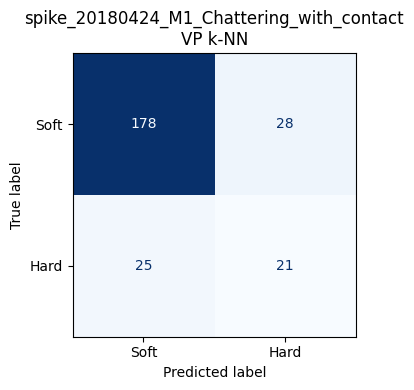

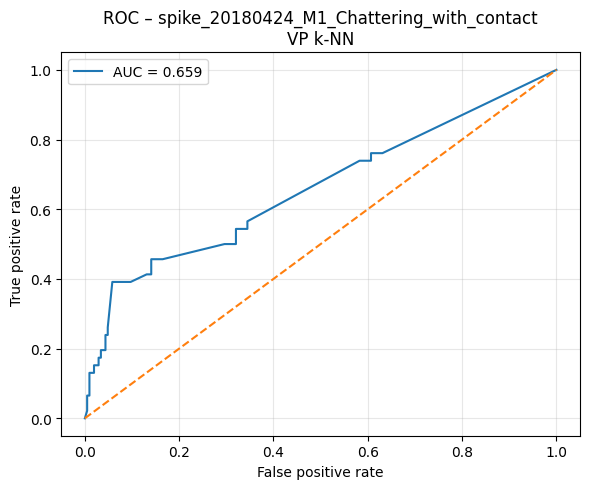

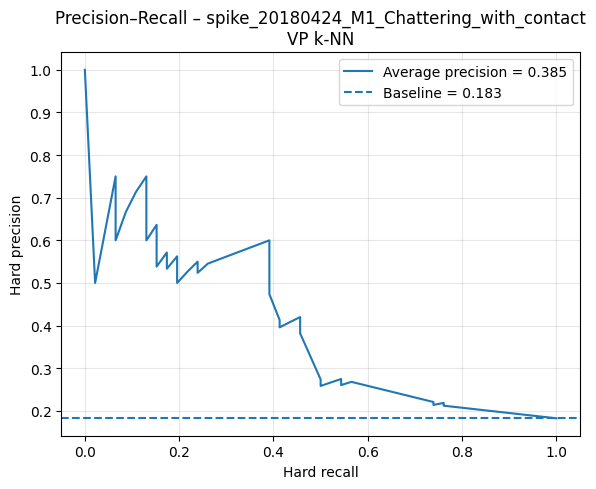



------------------------------------------------------------
MODEL: VP SVM
------------------------------------------------------------
Outer fold 1/5
Best parameters: {'q': 5, 'gamma_factor': 0.25, 'kernel_type': 'laplacian', 'C': 0.1, 'class_weight': {0: 1, 1: 3}, 'threshold': -0.75} | inner selection score = 0.589
Outer fold 2/5
Best parameters: {'q': 5, 'gamma_factor': 2, 'kernel_type': 'laplacian', 'C': 0.1, 'class_weight': {0: 1, 1: 3}, 'threshold': -0.75} | inner selection score = 0.625
Outer fold 3/5
Best parameters: {'q': 10, 'gamma_factor': 0.1, 'kernel_type': 'laplacian', 'C': 10, 'class_weight': {0: 1, 1: 2}, 'threshold': -0.75} | inner selection score = 0.597
Outer fold 4/5
Best parameters: {'q': 10, 'gamma_factor': 1, 'kernel_type': 'laplacian', 'C': 1, 'class_weight': 'balanced', 'threshold': 0.0} | inner selection score = 0.600
Outer fold 5/5
Best parameters: {'q': 10, 'gamma_factor': 2, 'kernel_type': 'laplacian', 'C': 0.1, 'class_weight': {0: 1, 1: 3}, 'threshold': 

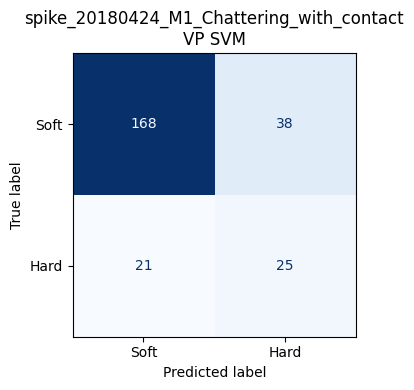

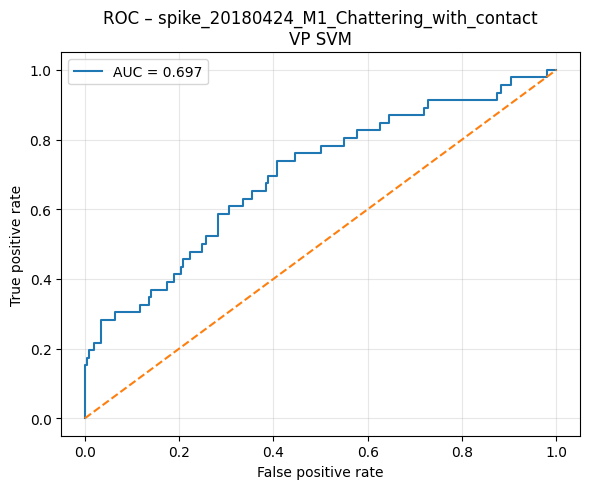

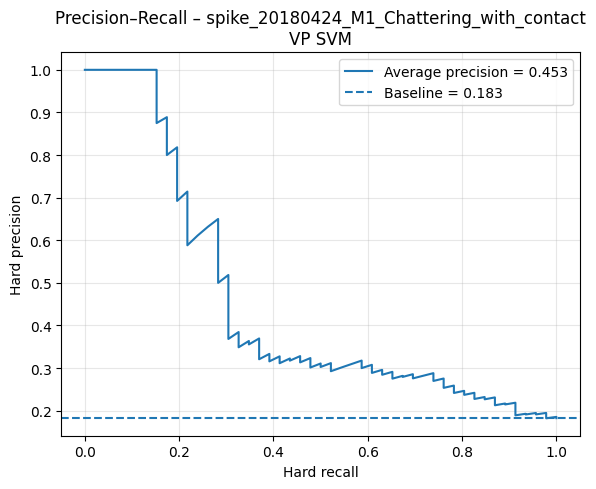


Dataset summary:
                                  dataset   model  n_samples  n_soft  n_hard  balanced_accuracy_mean  balanced_accuracy_std  precision_hard_mean  precision_hard_std  recall_hard_mean  recall_hard_std  f1_hard_mean  f1_hard_std  f15_hard_mean  f15_hard_std  specificity_soft_mean  specificity_soft_std  roc_auc_oof  average_precision_oof
spike_20180424_M1_Chattering_with_contact VP k-NN        252     206      46                0.659037               0.128101             0.540952            0.237490          0.453333         0.223248      0.455678     0.177634       0.447583      0.185463               0.864740              0.143319     0.658506               0.385091
spike_20180424_M1_Chattering_with_contact  VP SVM        252     206      46                0.677532               0.102593             0.427510            0.132286          0.540556         0.228181      0.454306     0.120091       0.478048      0.146510               0.814508              0.108529     0.6

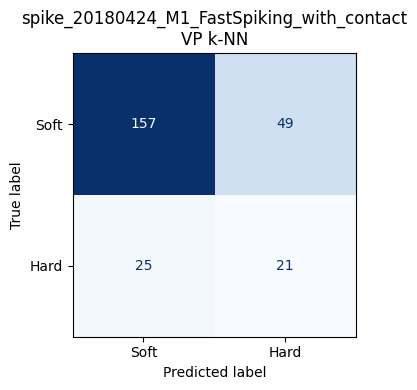

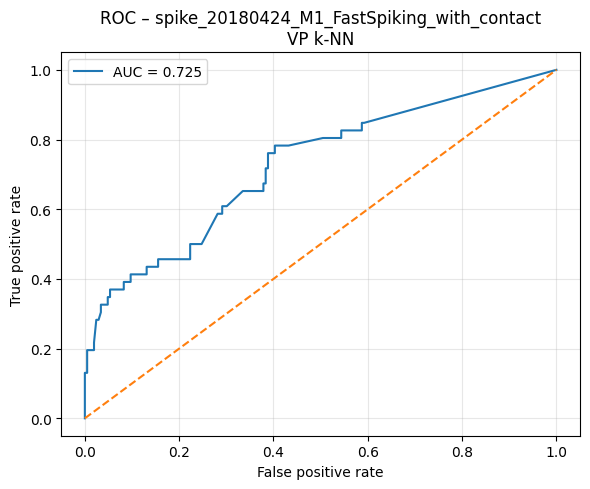

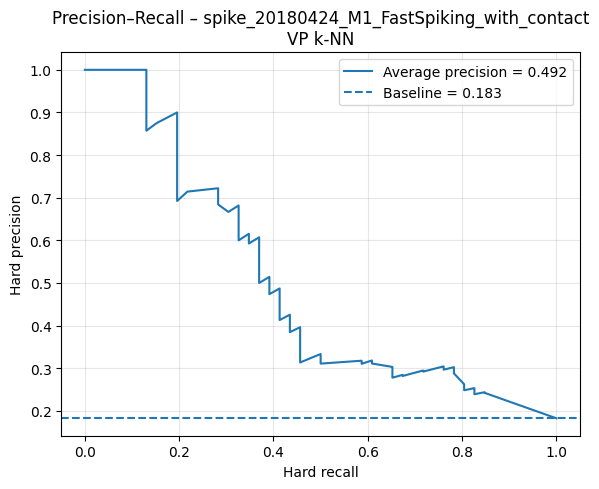



------------------------------------------------------------
MODEL: VP SVM
------------------------------------------------------------
Outer fold 1/5
Best parameters: {'q': 5, 'gamma_factor': 1, 'kernel_type': 'laplacian', 'C': 0.1, 'class_weight': {0: 1, 1: 3}, 'threshold': -0.75} | inner selection score = 0.586
Outer fold 2/5
Best parameters: {'q': 5, 'gamma_factor': 4, 'kernel_type': 'laplacian', 'C': 0.1, 'class_weight': {0: 1, 1: 3}, 'threshold': -0.75} | inner selection score = 0.605
Outer fold 3/5
Best parameters: {'q': 5, 'gamma_factor': 0.25, 'kernel_type': 'laplacian', 'C': 10, 'class_weight': {0: 1, 1: 5}, 'threshold': -0.25} | inner selection score = 0.601
Outer fold 4/5
Best parameters: {'q': 10, 'gamma_factor': 2, 'kernel_type': 'laplacian', 'C': 0.1, 'class_weight': {0: 1, 1: 3}, 'threshold': -0.75} | inner selection score = 0.581
Outer fold 5/5
Best parameters: {'q': 5, 'gamma_factor': 1, 'kernel_type': 'laplacian', 'C': 0.1, 'class_weight': {0: 1, 1: 3}, 'threshold'

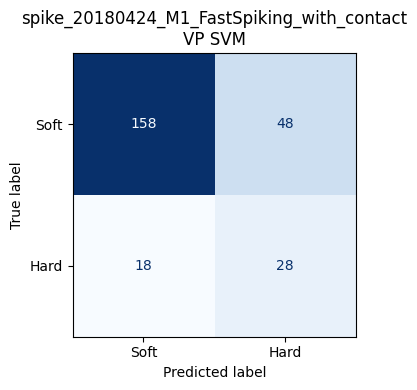

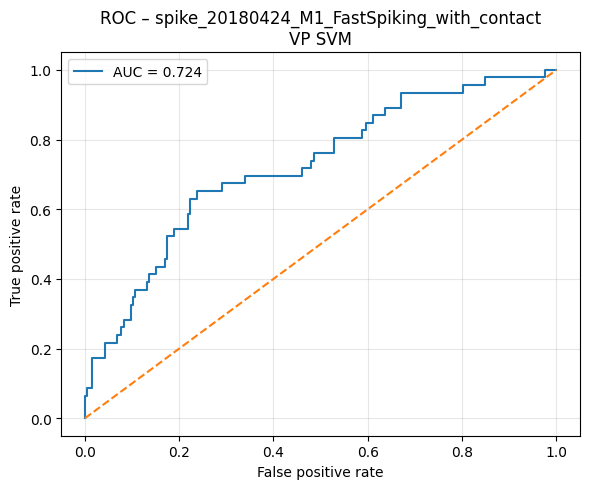

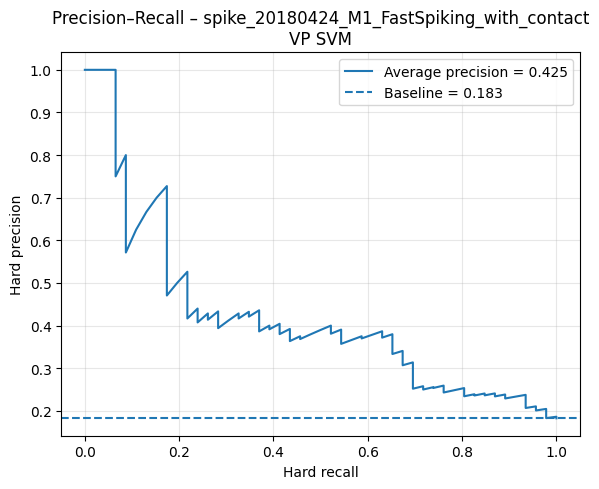


Dataset summary:
                                   dataset   model  n_samples  n_soft  n_hard  balanced_accuracy_mean  balanced_accuracy_std  precision_hard_mean  precision_hard_std  recall_hard_mean  recall_hard_std  f1_hard_mean  f1_hard_std  f15_hard_mean  f15_hard_std  specificity_soft_mean  specificity_soft_std  roc_auc_oof  average_precision_oof
spike_20180424_M1_FastSpiking_with_contact VP k-NN        252     206      46                0.608885               0.076904             0.298283            0.080495          0.455000         0.188197      0.354359     0.105741        0.38513      0.126843               0.762769              0.077416     0.724726               0.491557
spike_20180424_M1_FastSpiking_with_contact  VP SVM        252     206      46                0.687688               0.068413             0.386484            0.104384          0.609444         0.081546      0.468446     0.090615        0.51251      0.083176               0.765931              0.094987     

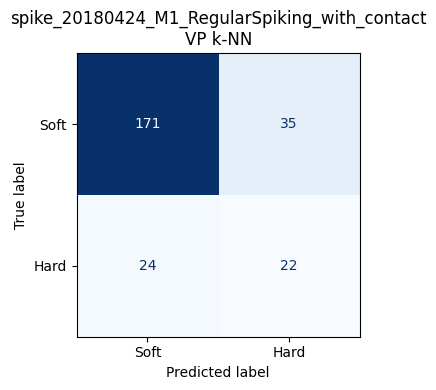

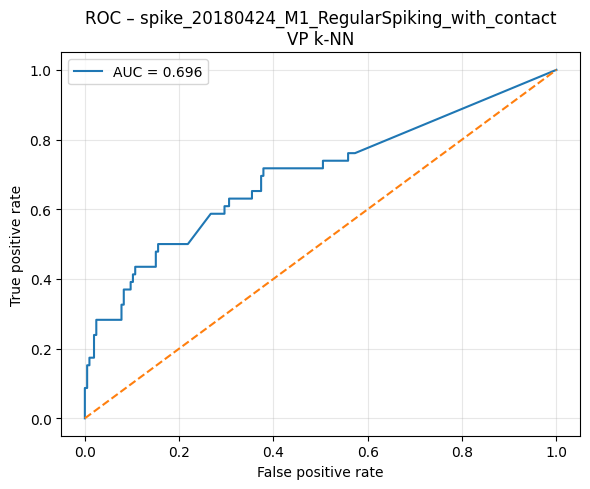

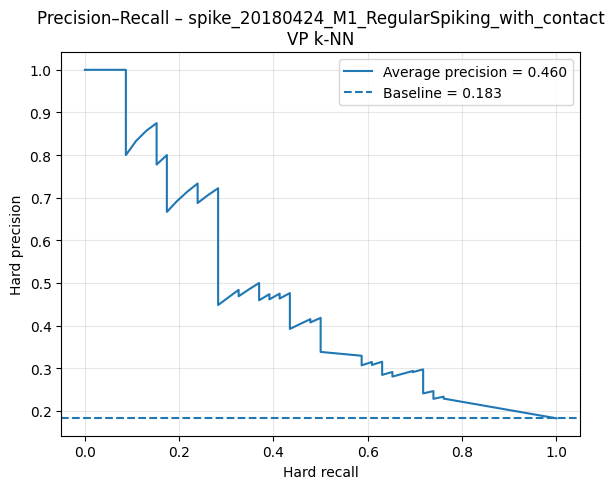



------------------------------------------------------------
MODEL: VP SVM
------------------------------------------------------------
Outer fold 1/5
Best parameters: {'q': 5, 'gamma_factor': 0.25, 'kernel_type': 'laplacian', 'C': 0.1, 'class_weight': {0: 1, 1: 3}, 'threshold': -0.75} | inner selection score = 0.589
Outer fold 2/5
Best parameters: {'q': 10, 'gamma_factor': 1, 'kernel_type': 'laplacian', 'C': 10, 'class_weight': {0: 1, 1: 2}, 'threshold': -0.5} | inner selection score = 0.631
Outer fold 3/5
Best parameters: {'q': 10, 'gamma_factor': 1, 'kernel_type': 'laplacian', 'C': 1, 'class_weight': {0: 1, 1: 2}, 'threshold': -0.5} | inner selection score = 0.507
Outer fold 4/5
Best parameters: {'q': 5, 'gamma_factor': 0.1, 'kernel_type': 'rbf_distance', 'C': 1, 'class_weight': {0: 1, 1: 2}, 'threshold': -0.5} | inner selection score = 0.624
Outer fold 5/5
Best parameters: {'q': 5, 'gamma_factor': 1, 'kernel_type': 'laplacian', 'C': 0.1, 'class_weight': {0: 1, 1: 3}, 'threshold':

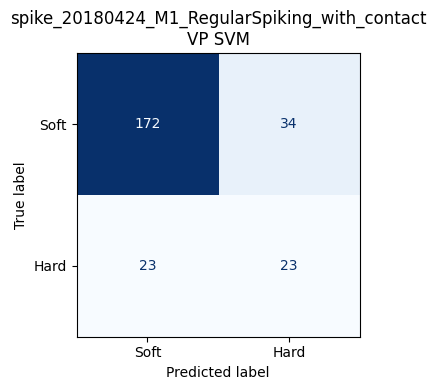

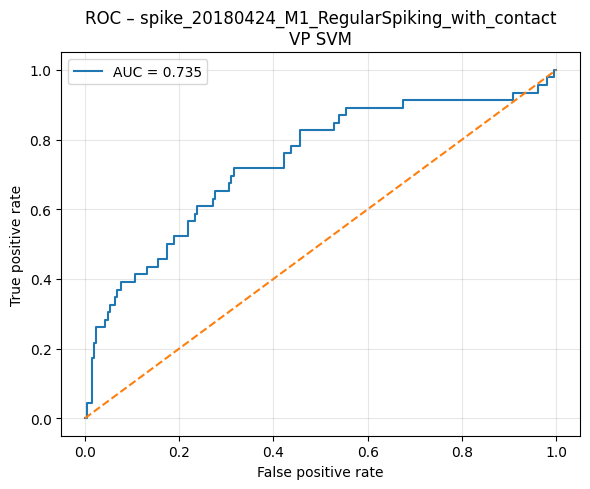

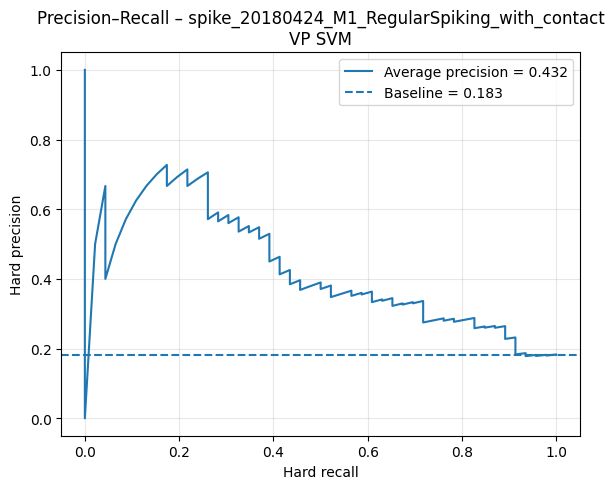


Dataset summary:
                                      dataset   model  n_samples  n_soft  n_hard  balanced_accuracy_mean  balanced_accuracy_std  precision_hard_mean  precision_hard_std  recall_hard_mean  recall_hard_std  f1_hard_mean  f1_hard_std  f15_hard_mean  f15_hard_std  specificity_soft_mean  specificity_soft_std  roc_auc_oof  average_precision_oof
spike_20180424_M1_RegularSpiking_with_contact VP k-NN        252     206      46                0.654324               0.107150             0.477778            0.313286          0.477778         0.228252      0.428100     0.148579       0.438442      0.163301               0.830869              0.107088     0.696074               0.459822
spike_20180424_M1_RegularSpiking_with_contact  VP SVM        252     206      46                0.665087               0.060026             0.425490            0.102965          0.495556         0.133009      0.444858     0.085747       0.459924      0.096930               0.834618              0.08

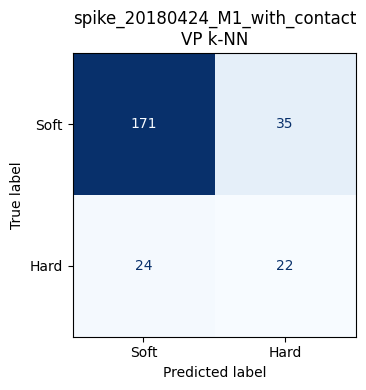

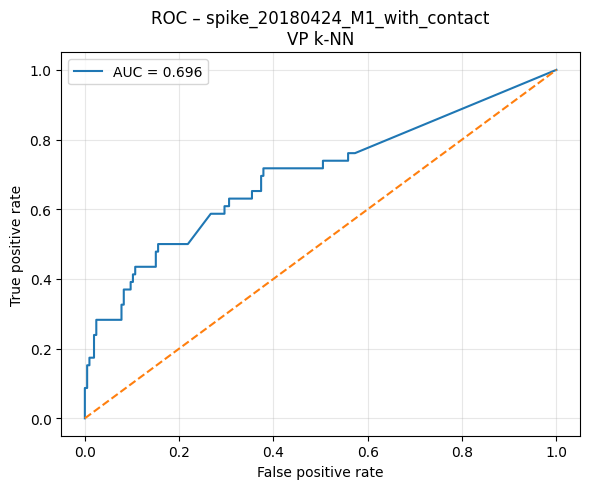

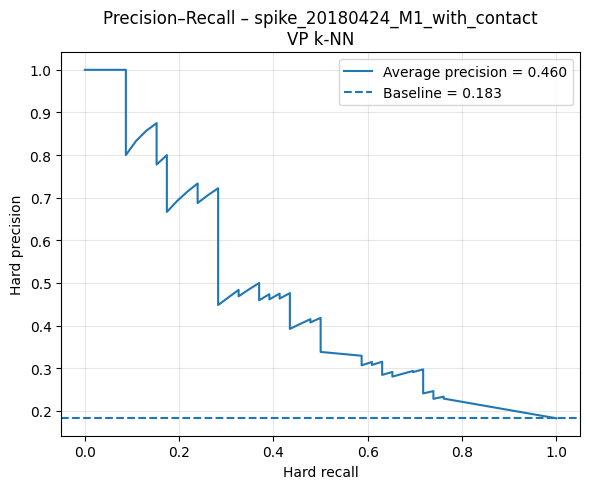



------------------------------------------------------------
MODEL: VP SVM
------------------------------------------------------------
Outer fold 1/5
Best parameters: {'q': 5, 'gamma_factor': 0.25, 'kernel_type': 'laplacian', 'C': 0.1, 'class_weight': {0: 1, 1: 3}, 'threshold': -0.75} | inner selection score = 0.589
Outer fold 2/5
Best parameters: {'q': 10, 'gamma_factor': 1, 'kernel_type': 'laplacian', 'C': 10, 'class_weight': {0: 1, 1: 2}, 'threshold': -0.5} | inner selection score = 0.631
Outer fold 3/5
Best parameters: {'q': 10, 'gamma_factor': 1, 'kernel_type': 'laplacian', 'C': 1, 'class_weight': {0: 1, 1: 2}, 'threshold': -0.5} | inner selection score = 0.507
Outer fold 4/5
Best parameters: {'q': 5, 'gamma_factor': 0.1, 'kernel_type': 'rbf_distance', 'C': 1, 'class_weight': {0: 1, 1: 2}, 'threshold': -0.5} | inner selection score = 0.624
Outer fold 5/5
Best parameters: {'q': 5, 'gamma_factor': 1, 'kernel_type': 'laplacian', 'C': 0.1, 'class_weight': {0: 1, 1: 3}, 'threshold':

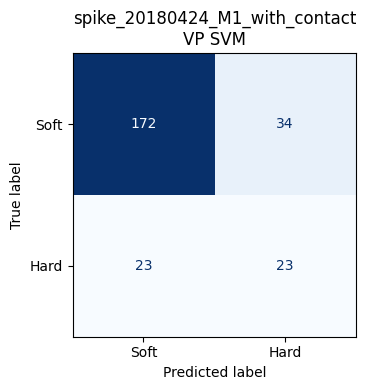

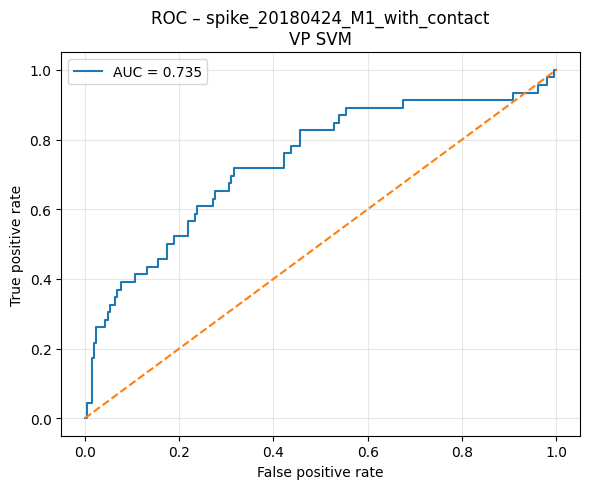

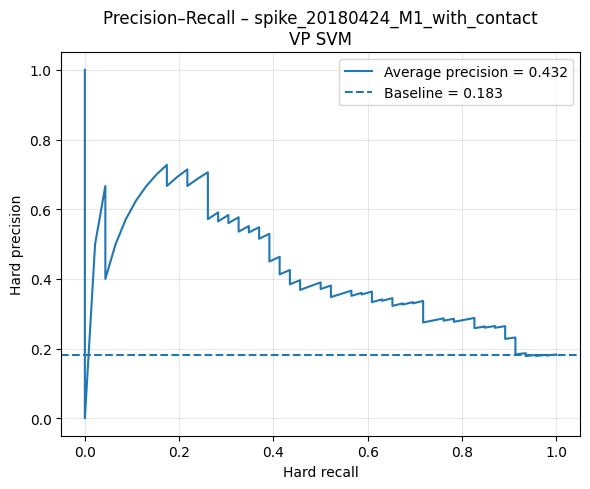


Dataset summary:
                       dataset   model  n_samples  n_soft  n_hard  balanced_accuracy_mean  balanced_accuracy_std  precision_hard_mean  precision_hard_std  recall_hard_mean  recall_hard_std  f1_hard_mean  f1_hard_std  f15_hard_mean  f15_hard_std  specificity_soft_mean  specificity_soft_std  roc_auc_oof  average_precision_oof
spike_20180424_M1_with_contact VP k-NN        252     206      46                0.654324               0.107150             0.477778            0.313286          0.477778         0.228252      0.428100     0.148579       0.438442      0.163301               0.830869              0.107088     0.696074               0.459822
spike_20180424_M1_with_contact  VP SVM        252     206      46                0.665087               0.060026             0.425490            0.102965          0.495556         0.133009      0.444858     0.085747       0.459924      0.096930               0.834618              0.085892     0.734909               0.432368


##

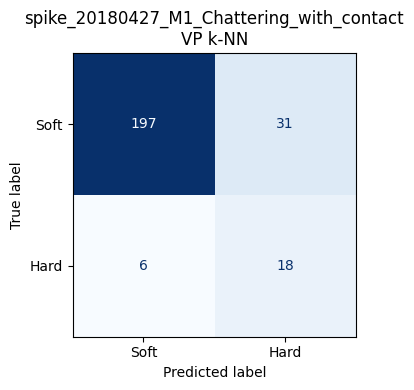

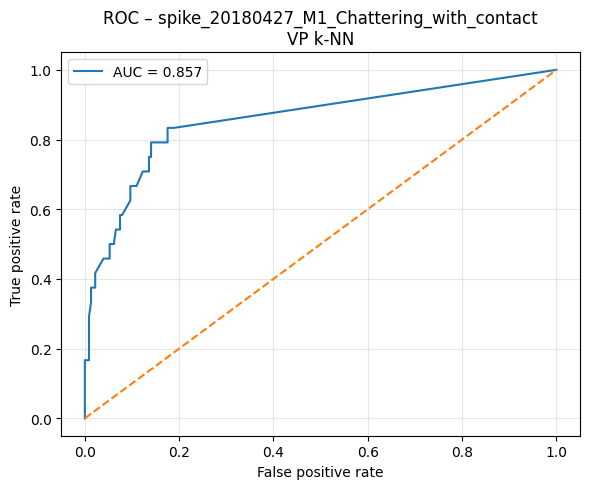

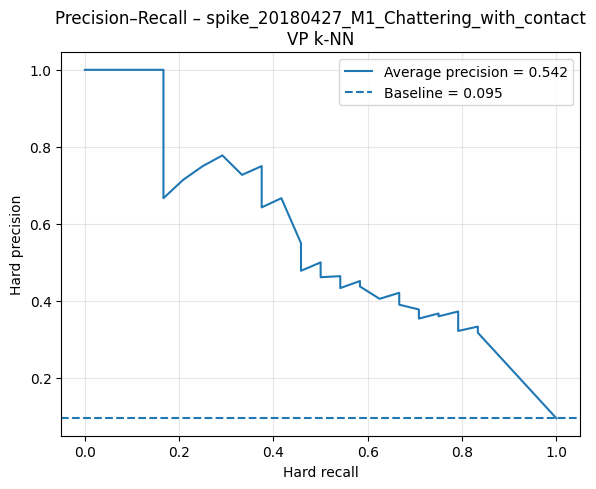



------------------------------------------------------------
MODEL: VP SVM
------------------------------------------------------------
Outer fold 1/5
Best parameters: {'q': 20, 'gamma_factor': 1, 'kernel_type': 'laplacian', 'C': 10, 'class_weight': {0: 1, 1: 2}, 'threshold': -0.5} | inner selection score = 0.760
Outer fold 2/5
Best parameters: {'q': 5, 'gamma_factor': 0.1, 'kernel_type': 'laplacian', 'C': 10, 'class_weight': {0: 1, 1: 2}, 'threshold': -0.75} | inner selection score = 0.721
Outer fold 3/5
Best parameters: {'q': 5, 'gamma_factor': 0.5, 'kernel_type': 'laplacian', 'C': 1, 'class_weight': 'balanced', 'threshold': -0.25} | inner selection score = 0.599
Outer fold 4/5
Best parameters: {'q': 10, 'gamma_factor': 0.5, 'kernel_type': 'laplacian', 'C': 100, 'class_weight': {0: 1, 1: 2}, 'threshold': -0.5} | inner selection score = 0.760
Outer fold 5/5
Best parameters: {'q': 5, 'gamma_factor': 0.5, 'kernel_type': 'laplacian', 'C': 1, 'class_weight': 'balanced', 'threshold': 0.0

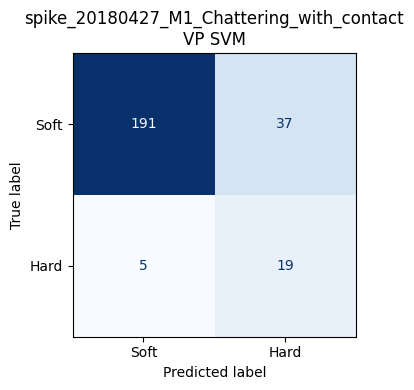

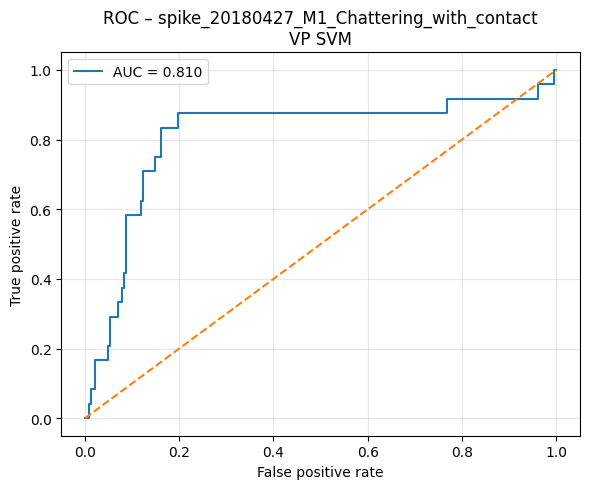

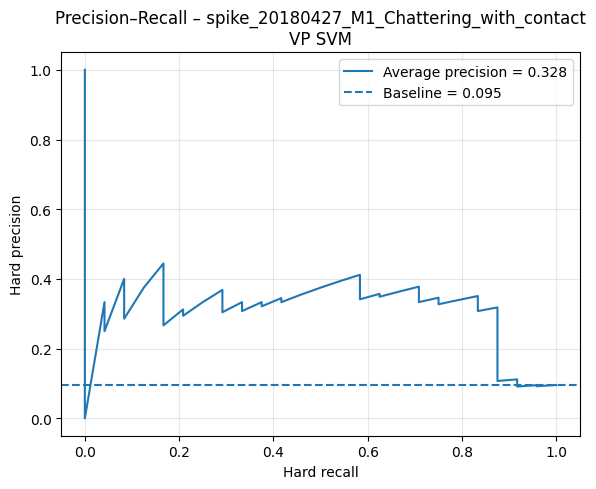


Dataset summary:
                                  dataset   model  n_samples  n_soft  n_hard  balanced_accuracy_mean  balanced_accuracy_std  precision_hard_mean  precision_hard_std  recall_hard_mean  recall_hard_std  f1_hard_mean  f1_hard_std  f15_hard_mean  f15_hard_std  specificity_soft_mean  specificity_soft_std  roc_auc_oof  average_precision_oof
spike_20180427_M1_Chattering_with_contact VP k-NN        252     228      24                0.810823               0.098622             0.392251            0.184893          0.756667         0.168984      0.503409     0.163282       0.572506      0.151504               0.864978              0.054653     0.857365               0.542097
spike_20180427_M1_Chattering_with_contact  VP SVM        252     228      24                0.813664               0.116846             0.333364            0.077152          0.790000         0.245967      0.466032     0.115364       0.551748      0.144271               0.837327              0.035314     0.8

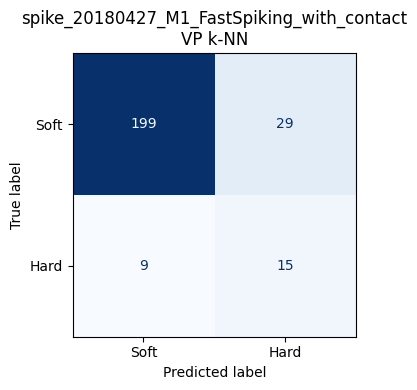

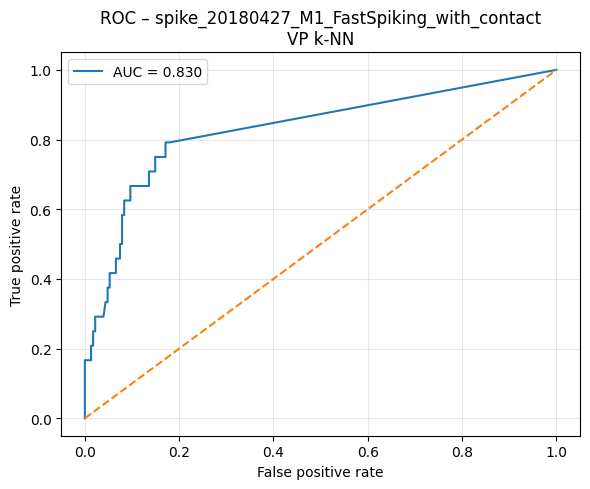

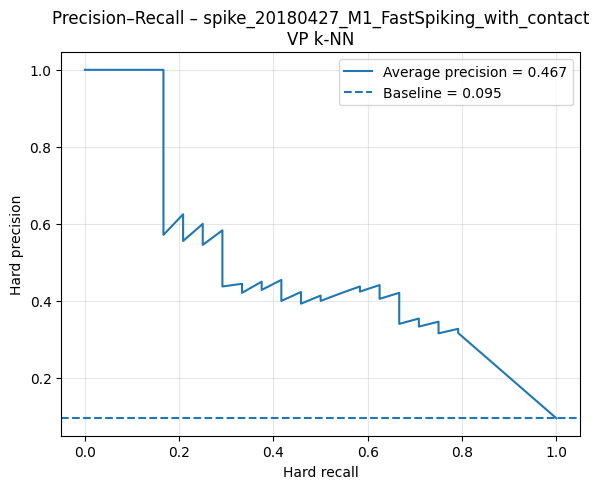



------------------------------------------------------------
MODEL: VP SVM
------------------------------------------------------------
Outer fold 1/5
Best parameters: {'q': 5, 'gamma_factor': 0.25, 'kernel_type': 'laplacian', 'C': 100, 'class_weight': {0: 1, 1: 2}, 'threshold': -0.75} | inner selection score = 0.799
Outer fold 2/5
Best parameters: {'q': 20, 'gamma_factor': 0.25, 'kernel_type': 'laplacian', 'C': 1, 'class_weight': {0: 1, 1: 3}, 'threshold': -0.75} | inner selection score = 0.736
Outer fold 3/5
Best parameters: {'q': 5, 'gamma_factor': 0.1, 'kernel_type': 'rbf_distance', 'C': 100, 'class_weight': {0: 1, 1: 2}, 'threshold': -0.5} | inner selection score = 0.630
Outer fold 4/5
Best parameters: {'q': 10, 'gamma_factor': 0.25, 'kernel_type': 'laplacian', 'C': 10, 'class_weight': {0: 1, 1: 2}, 'threshold': -0.75} | inner selection score = 0.748
Outer fold 5/5
Best parameters: {'q': 20, 'gamma_factor': 0.1, 'kernel_type': 'laplacian', 'C': 100, 'class_weight': {0: 1, 1: 2},

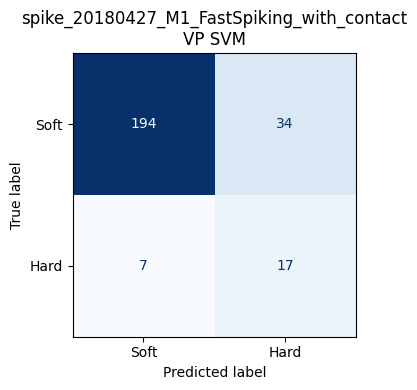

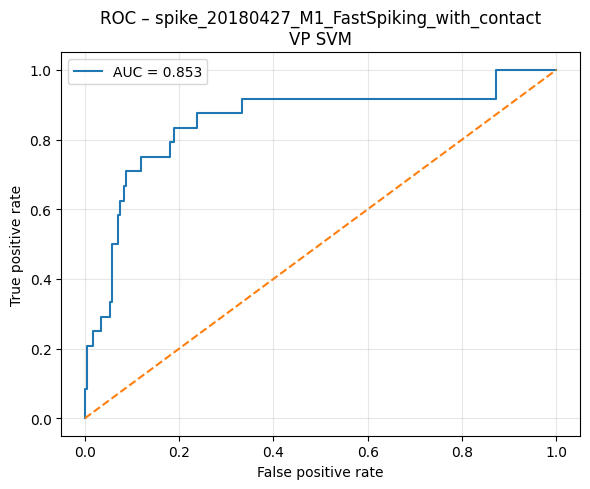

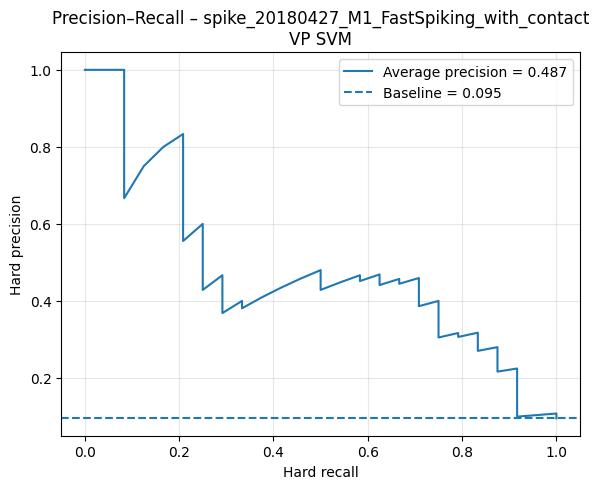


Dataset summary:
                                   dataset   model  n_samples  n_soft  n_hard  balanced_accuracy_mean  balanced_accuracy_std  precision_hard_mean  precision_hard_std  recall_hard_mean  recall_hard_std  f1_hard_mean  f1_hard_std  f15_hard_mean  f15_hard_std  specificity_soft_mean  specificity_soft_std  roc_auc_oof  average_precision_oof
spike_20180427_M1_FastSpiking_with_contact VP k-NN        252     228      24                0.758451               0.131299             0.349697            0.116017          0.643333         0.253750      0.443606     0.138634       0.499895      0.162022               0.873569              0.041641     0.830044               0.467391
spike_20180427_M1_FastSpiking_with_contact  VP SVM        252     228      24                0.779303               0.069664             0.364069            0.198723          0.706667         0.103145      0.464560     0.171888       0.528188      0.148664               0.851939              0.062780     

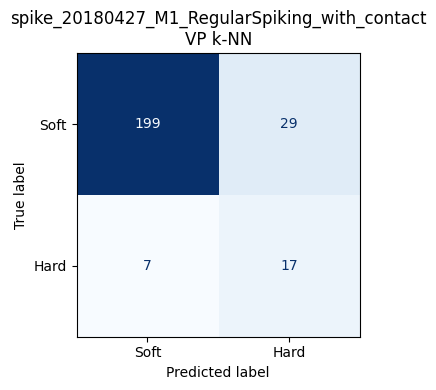

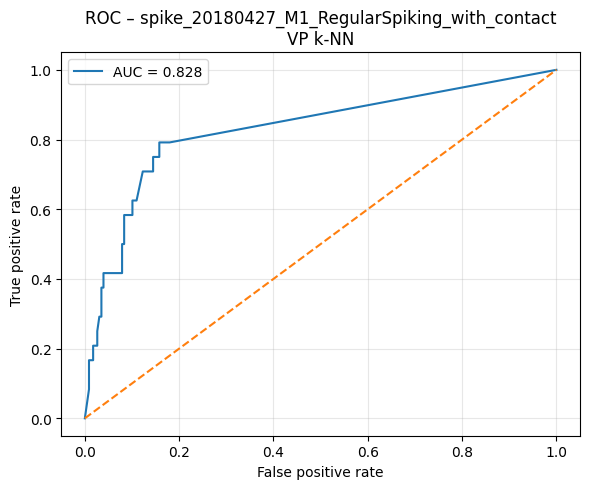

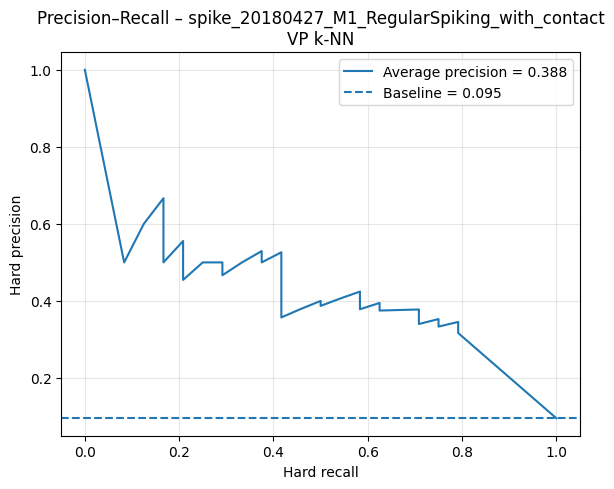



------------------------------------------------------------
MODEL: VP SVM
------------------------------------------------------------
Outer fold 1/5
Best parameters: {'q': 20, 'gamma_factor': 0.5, 'kernel_type': 'laplacian', 'C': 10, 'class_weight': {0: 1, 1: 3}, 'threshold': -0.5} | inner selection score = 0.730
Outer fold 2/5
Best parameters: {'q': 10, 'gamma_factor': 0.25, 'kernel_type': 'laplacian', 'C': 1, 'class_weight': {0: 1, 1: 3}, 'threshold': -0.75} | inner selection score = 0.738
Outer fold 3/5
Best parameters: {'q': 5, 'gamma_factor': 0.1, 'kernel_type': 'rbf_distance', 'C': 100, 'class_weight': {0: 1, 1: 3}, 'threshold': -0.25} | inner selection score = 0.583
Outer fold 4/5
Best parameters: {'q': 10, 'gamma_factor': 1, 'kernel_type': 'laplacian', 'C': 1, 'class_weight': {0: 1, 1: 3}, 'threshold': -0.5} | inner selection score = 0.728
Outer fold 5/5
Best parameters: {'q': 10, 'gamma_factor': 0.25, 'kernel_type': 'laplacian', 'C': 10, 'class_weight': {0: 1, 1: 2}, 'thre

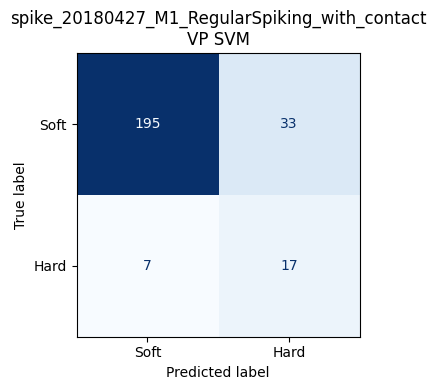

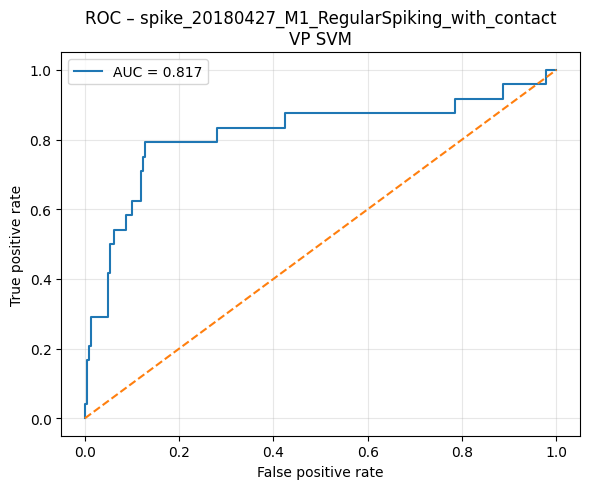

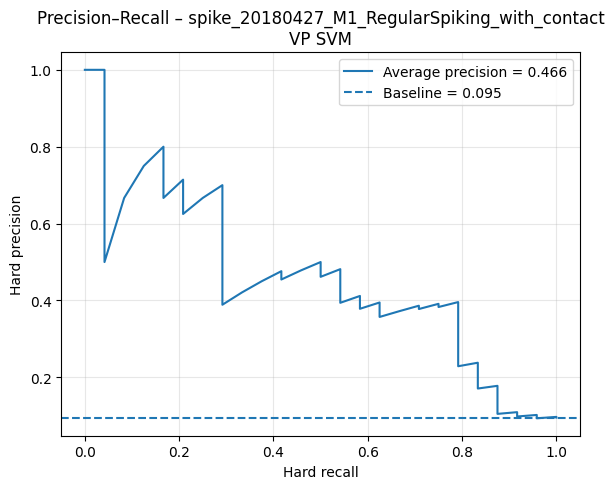


Dataset summary:
                                      dataset   model  n_samples  n_soft  n_hard  balanced_accuracy_mean  balanced_accuracy_std  precision_hard_mean  precision_hard_std  recall_hard_mean  recall_hard_std  f1_hard_mean  f1_hard_std  f15_hard_mean  f15_hard_std  specificity_soft_mean  specificity_soft_std  roc_auc_oof  average_precision_oof
spike_20180427_M1_RegularSpiking_with_contact VP k-NN        252     228      24                0.794783               0.112374             0.364394            0.090212          0.716667         0.228522      0.478919     0.118952       0.546833      0.141690               0.872900              0.017233     0.828399               0.388026
spike_20180427_M1_RegularSpiking_with_contact  VP SVM        252     228      24                0.779522               0.087668             0.352320            0.138570          0.703333         0.189444      0.456441     0.127105       0.522226      0.127837               0.855711              0.04

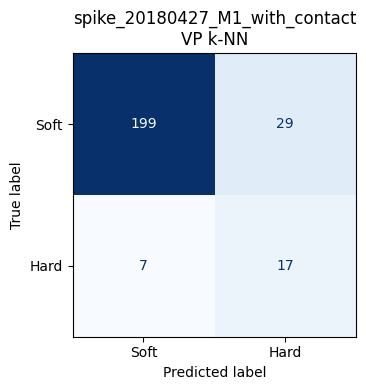

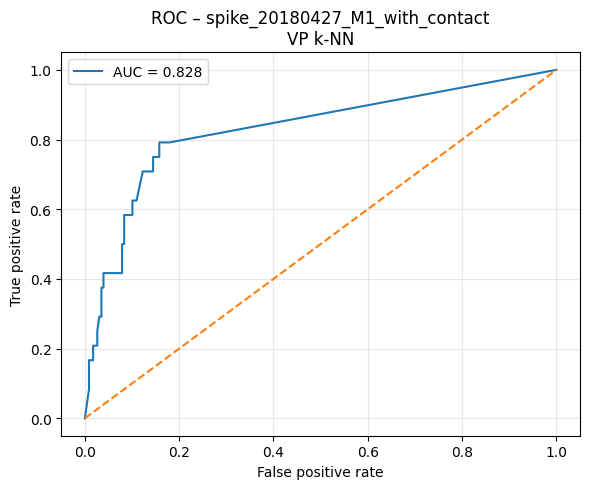

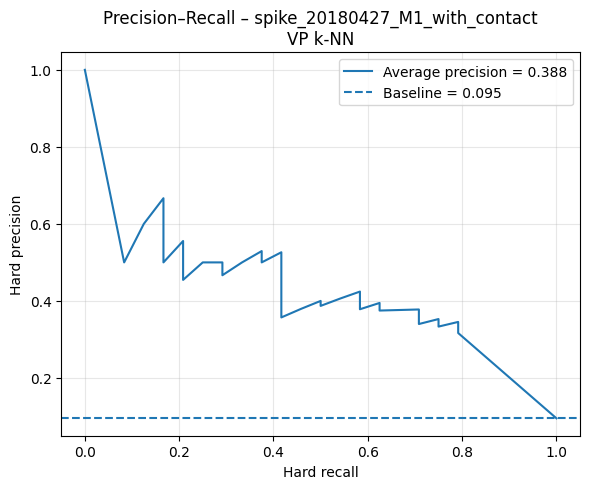



------------------------------------------------------------
MODEL: VP SVM
------------------------------------------------------------
Outer fold 1/5
Best parameters: {'q': 20, 'gamma_factor': 0.5, 'kernel_type': 'laplacian', 'C': 10, 'class_weight': {0: 1, 1: 3}, 'threshold': -0.5} | inner selection score = 0.730
Outer fold 2/5
Best parameters: {'q': 10, 'gamma_factor': 0.25, 'kernel_type': 'laplacian', 'C': 1, 'class_weight': {0: 1, 1: 3}, 'threshold': -0.75} | inner selection score = 0.738
Outer fold 3/5
Best parameters: {'q': 5, 'gamma_factor': 0.1, 'kernel_type': 'rbf_distance', 'C': 100, 'class_weight': {0: 1, 1: 3}, 'threshold': -0.25} | inner selection score = 0.583
Outer fold 4/5
Best parameters: {'q': 10, 'gamma_factor': 1, 'kernel_type': 'laplacian', 'C': 1, 'class_weight': {0: 1, 1: 3}, 'threshold': -0.5} | inner selection score = 0.728
Outer fold 5/5
Best parameters: {'q': 10, 'gamma_factor': 0.25, 'kernel_type': 'laplacian', 'C': 10, 'class_weight': {0: 1, 1: 2}, 'thre

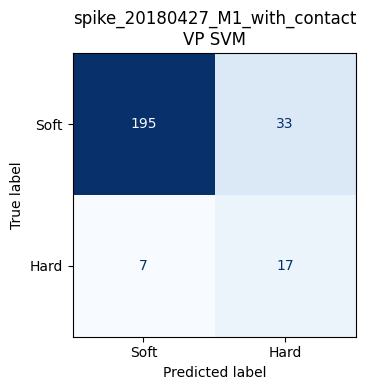

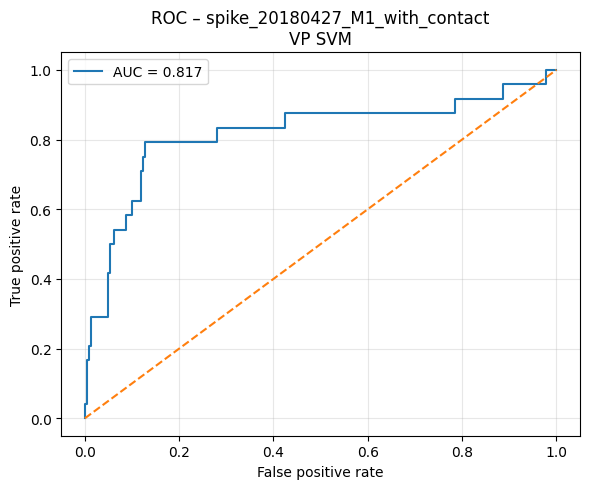

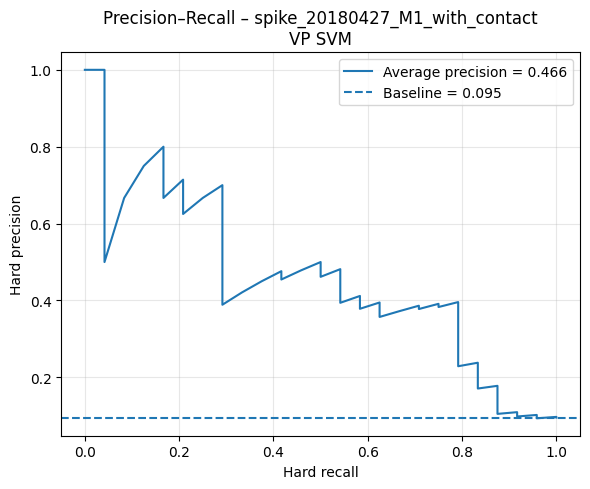


Dataset summary:
                       dataset   model  n_samples  n_soft  n_hard  balanced_accuracy_mean  balanced_accuracy_std  precision_hard_mean  precision_hard_std  recall_hard_mean  recall_hard_std  f1_hard_mean  f1_hard_std  f15_hard_mean  f15_hard_std  specificity_soft_mean  specificity_soft_std  roc_auc_oof  average_precision_oof
spike_20180427_M1_with_contact VP k-NN        252     228      24                0.794783               0.112374             0.364394            0.090212          0.716667         0.228522      0.478919     0.118952       0.546833      0.141690               0.872900              0.017233     0.828399               0.388026
spike_20180427_M1_with_contact  VP SVM        252     228      24                0.779522               0.087668             0.352320            0.138570          0.703333         0.189444      0.456441     0.127105       0.522226      0.127837               0.855711              0.049726     0.817069               0.465900


##

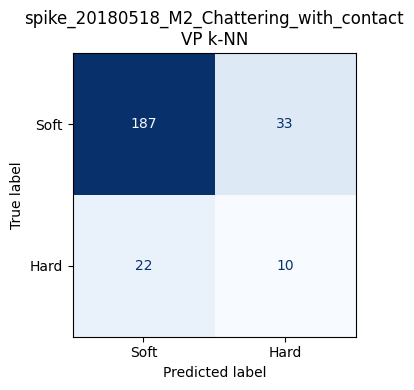

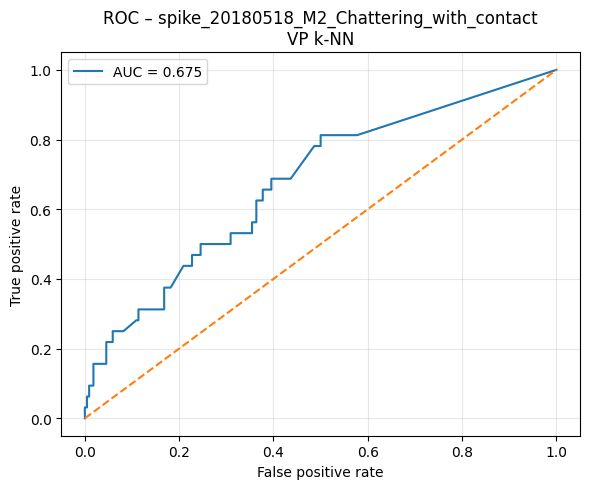

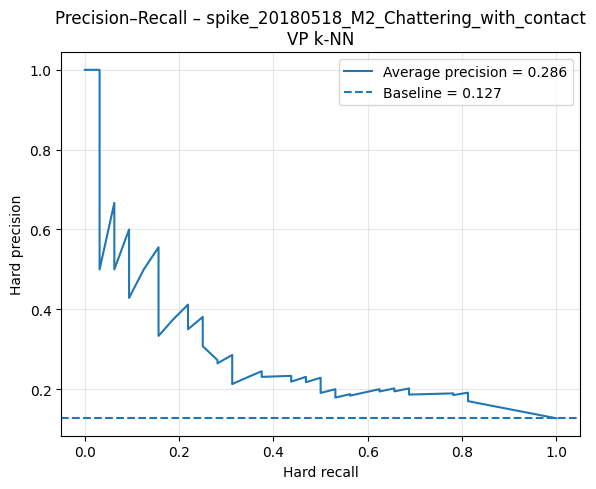



------------------------------------------------------------
MODEL: VP SVM
------------------------------------------------------------
Outer fold 1/5
Best parameters: {'q': 20, 'gamma_factor': 4, 'kernel_type': 'laplacian', 'C': 1, 'class_weight': 'balanced', 'threshold': -0.25} | inner selection score = 0.294
Outer fold 2/5
Best parameters: {'q': 20, 'gamma_factor': 0.25, 'kernel_type': 'laplacian', 'C': 1, 'class_weight': {0: 1, 1: 3}, 'threshold': -0.75} | inner selection score = 0.540
Outer fold 3/5
Best parameters: {'q': 5, 'gamma_factor': 1, 'kernel_type': 'laplacian', 'C': 10, 'class_weight': {0: 1, 1: 2}, 'threshold': -0.25} | inner selection score = 0.549
Outer fold 4/5
Best parameters: {'q': 5, 'gamma_factor': 1, 'kernel_type': 'laplacian', 'C': 10, 'class_weight': 'balanced', 'threshold': -0.25} | inner selection score = 0.546
Outer fold 5/5
Best parameters: {'q': 5, 'gamma_factor': 0.5, 'kernel_type': 'laplacian', 'C': 10, 'class_weight': {0: 1, 1: 2}, 'threshold': -0.25

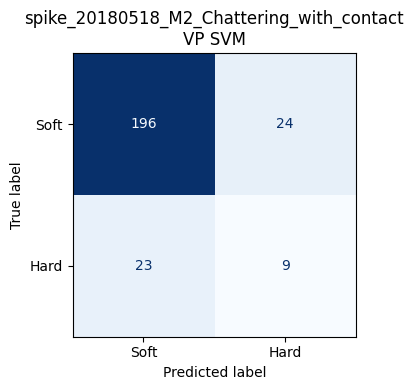

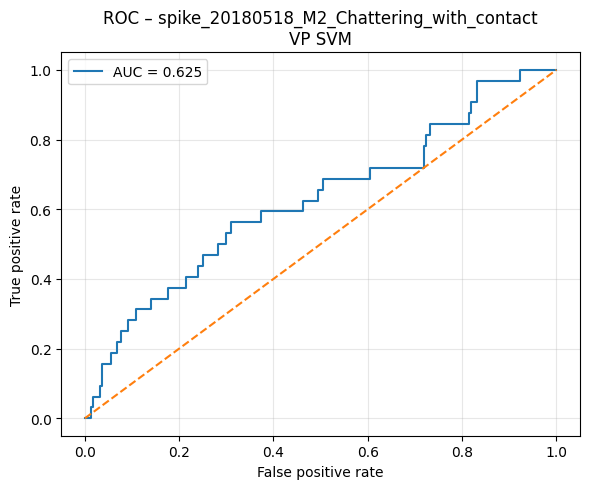

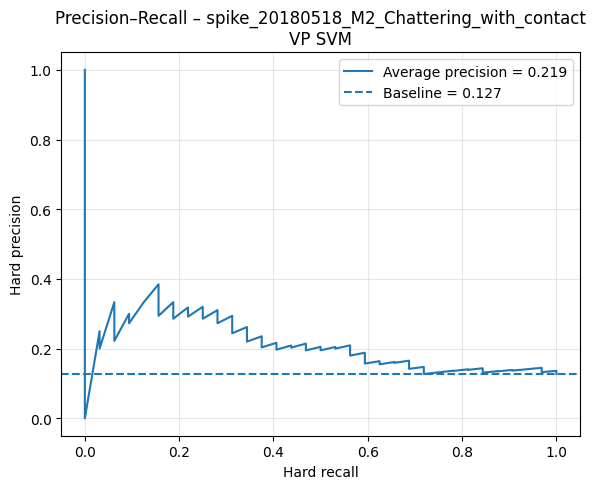


Dataset summary:
                                  dataset   model  n_samples  n_soft  n_hard  balanced_accuracy_mean  balanced_accuracy_std  precision_hard_mean  precision_hard_std  recall_hard_mean  recall_hard_std  f1_hard_mean  f1_hard_std  f15_hard_mean  f15_hard_std  specificity_soft_mean  specificity_soft_std  roc_auc_oof  average_precision_oof
spike_20180518_M2_Chattering_with_contact VP k-NN        252     220      32                0.584582                0.06752             0.245769            0.082585          0.319048         0.127775      0.269221     0.098062       0.284611      0.108092               0.850115              0.067546     0.675355               0.286028
spike_20180518_M2_Chattering_with_contact  VP SVM        252     220      32                0.585685                0.02549             0.411212            0.332609          0.280952         0.121871      0.268254     0.042795       0.266881      0.072582               0.890418              0.082305     0.6

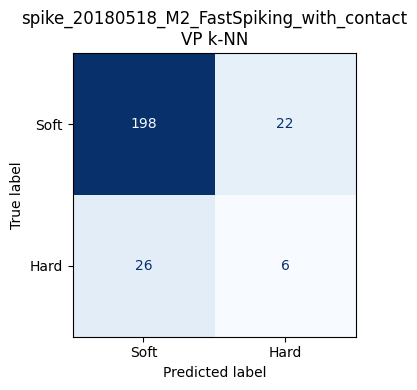

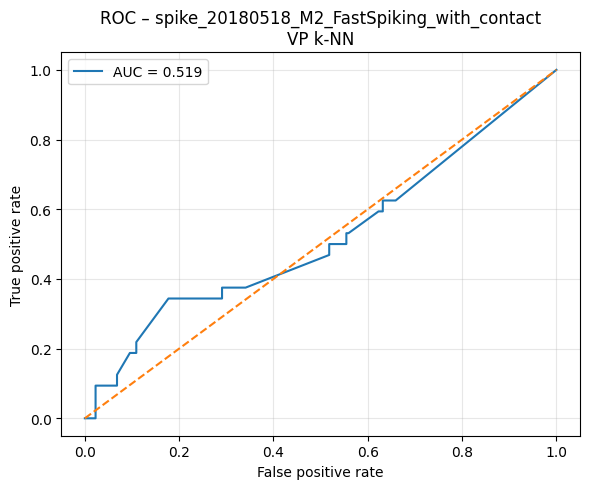

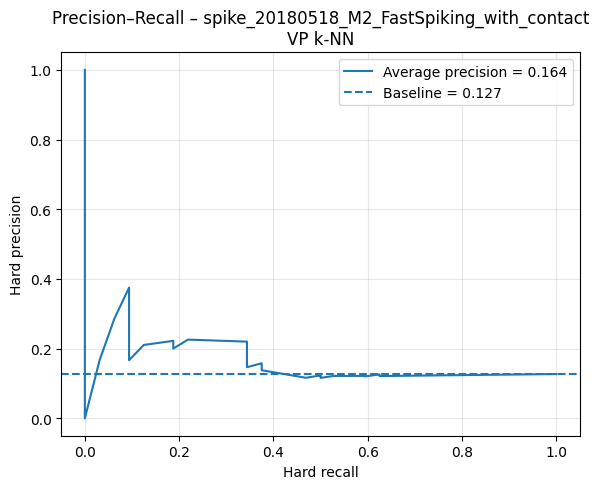



------------------------------------------------------------
MODEL: VP SVM
------------------------------------------------------------
Outer fold 1/5
Best parameters: {'q': 10, 'gamma_factor': 0.25, 'kernel_type': 'laplacian', 'C': 10, 'class_weight': 'balanced', 'threshold': 0.25} | inner selection score = 0.034
Outer fold 2/5
Best parameters: {'q': 5, 'gamma_factor': 0.25, 'kernel_type': 'laplacian', 'C': 10, 'class_weight': {0: 1, 1: 2}, 'threshold': -0.5} | inner selection score = 0.109
Outer fold 3/5
Best parameters: {'q': 5, 'gamma_factor': 0.5, 'kernel_type': 'laplacian', 'C': 10, 'class_weight': 'balanced', 'threshold': 0.25} | inner selection score = 0.308
Outer fold 4/5
Best parameters: {'q': 20, 'gamma_factor': 0.25, 'kernel_type': 'laplacian', 'C': 10, 'class_weight': {0: 1, 1: 2}, 'threshold': -0.5} | inner selection score = 0.393
Outer fold 5/5
Best parameters: {'q': 5, 'gamma_factor': 0.1, 'kernel_type': 'laplacian', 'C': 100, 'class_weight': {0: 1, 1: 3}, 'threshold'

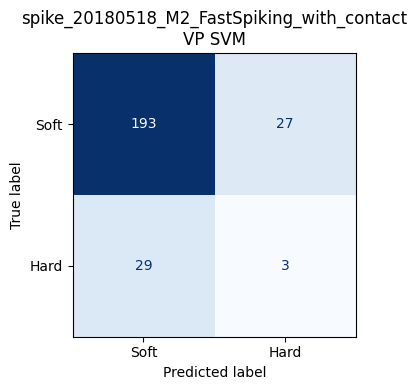

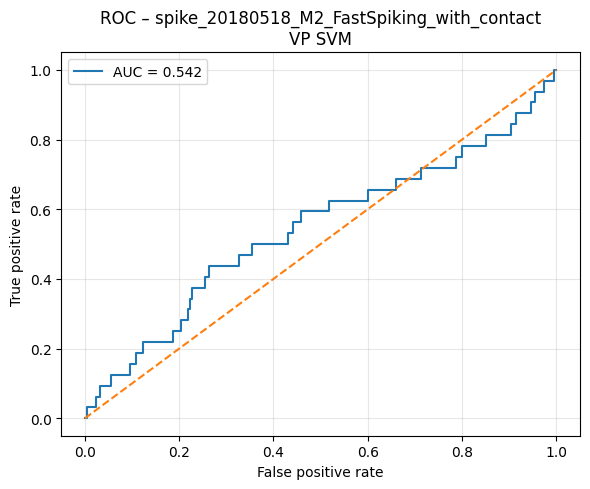

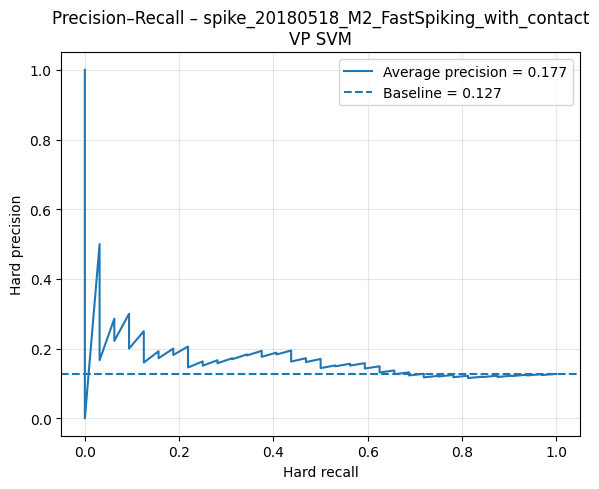


Dataset summary:
                                   dataset   model  n_samples  n_soft  n_hard  balanced_accuracy_mean  balanced_accuracy_std  precision_hard_mean  precision_hard_std  recall_hard_mean  recall_hard_std  f1_hard_mean  f1_hard_std  f15_hard_mean  f15_hard_std  specificity_soft_mean  specificity_soft_std  roc_auc_oof  average_precision_oof
spike_20180518_M2_FastSpiking_with_contact VP k-NN        252     220      32                0.545296               0.064281                 0.29            0.213307          0.190476         0.129319      0.204202     0.115655       0.194822      0.115404               0.900115              0.072352     0.518679               0.163545
spike_20180518_M2_FastSpiking_with_contact  VP SVM        252     220      32                0.483196               0.101595                 0.18            0.248998          0.090476         0.130844      0.116667     0.162447       0.104586      0.147818               0.875916              0.086704     

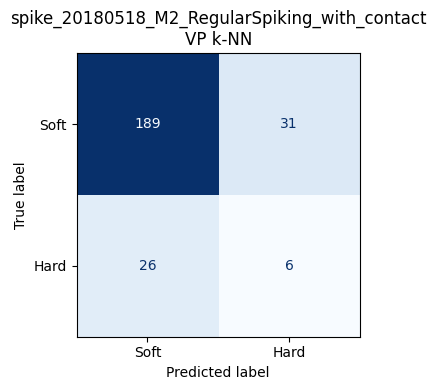

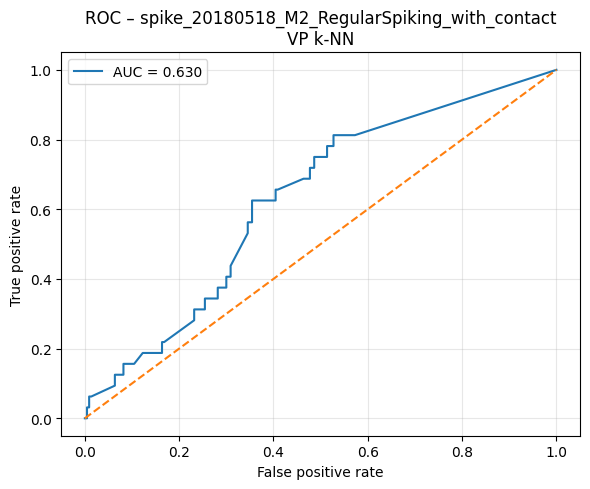

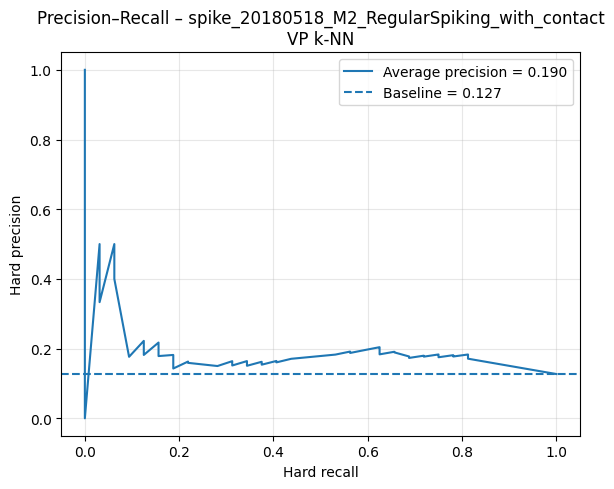



------------------------------------------------------------
MODEL: VP SVM
------------------------------------------------------------
Outer fold 1/5
Best parameters: {'q': 10, 'gamma_factor': 0.1, 'kernel_type': 'rbf_distance', 'C': 1, 'class_weight': {0: 1, 1: 3}, 'threshold': -0.25} | inner selection score = 0.352
Outer fold 2/5
Best parameters: {'q': 5, 'gamma_factor': 0.1, 'kernel_type': 'rbf_distance', 'C': 0.1, 'class_weight': {0: 1, 1: 5}, 'threshold': 0.0} | inner selection score = 0.418
Outer fold 3/5
Best parameters: {'q': 20, 'gamma_factor': 4, 'kernel_type': 'laplacian', 'C': 0.1, 'class_weight': {0: 1, 1: 5}, 'threshold': -0.75} | inner selection score = 0.428
Outer fold 4/5
Best parameters: {'q': 5, 'gamma_factor': 0.1, 'kernel_type': 'rbf_distance', 'C': 10, 'class_weight': {0: 1, 1: 2}, 'threshold': -0.25} | inner selection score = 0.361
Outer fold 5/5
Best parameters: {'q': 20, 'gamma_factor': 1, 'kernel_type': 'laplacian', 'C': 1, 'class_weight': {0: 1, 1: 3}, 'th

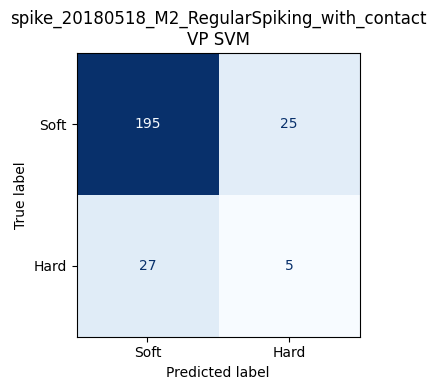

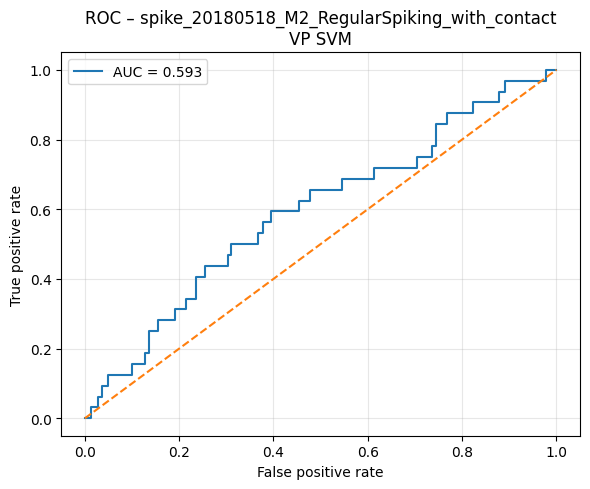

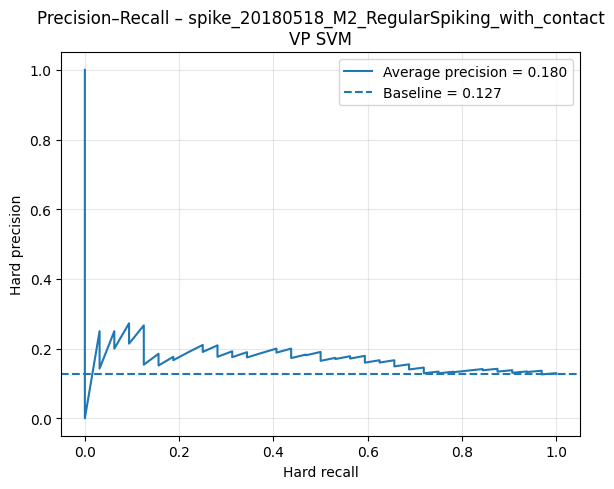


Dataset summary:
                                      dataset   model  n_samples  n_soft  n_hard  balanced_accuracy_mean  balanced_accuracy_std  precision_hard_mean  precision_hard_std  recall_hard_mean  recall_hard_std  f1_hard_mean  f1_hard_std  f15_hard_mean  f15_hard_std  specificity_soft_mean  specificity_soft_std  roc_auc_oof  average_precision_oof
spike_20180518_M2_RegularSpiking_with_contact VP k-NN        252     220      32                0.522042               0.056634             0.200794            0.122811          0.185714         0.056844      0.183443     0.081135       0.182115      0.070350               0.858369              0.080979     0.629616               0.190109
spike_20180518_M2_RegularSpiking_with_contact  VP SVM        252     220      32                0.519221               0.038509             0.143571            0.094167          0.152381         0.101854      0.146840     0.096405       0.148676      0.098108               0.886061              0.04

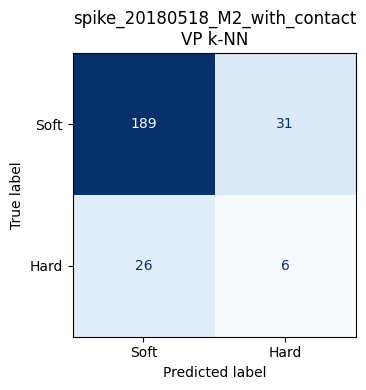

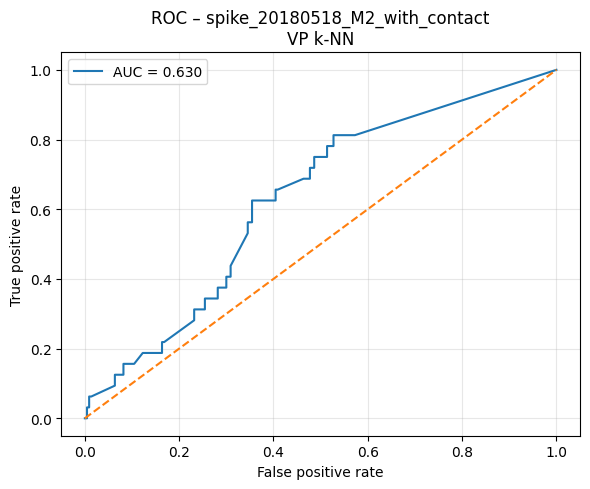

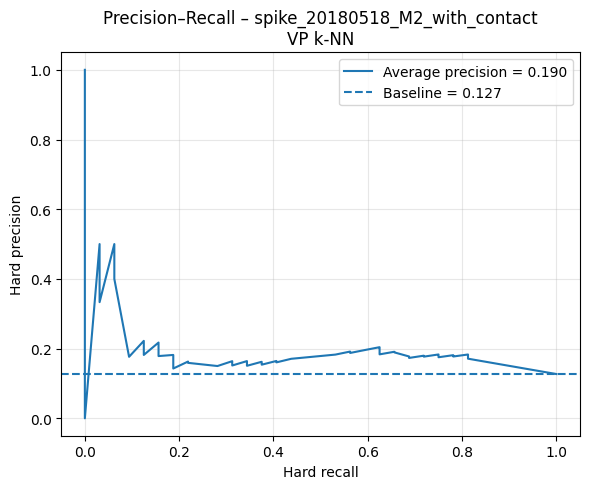



------------------------------------------------------------
MODEL: VP SVM
------------------------------------------------------------
Outer fold 1/5
Best parameters: {'q': 10, 'gamma_factor': 0.1, 'kernel_type': 'rbf_distance', 'C': 1, 'class_weight': {0: 1, 1: 3}, 'threshold': -0.25} | inner selection score = 0.352
Outer fold 2/5
Best parameters: {'q': 5, 'gamma_factor': 0.1, 'kernel_type': 'rbf_distance', 'C': 0.1, 'class_weight': {0: 1, 1: 5}, 'threshold': 0.0} | inner selection score = 0.418
Outer fold 3/5
Best parameters: {'q': 20, 'gamma_factor': 4, 'kernel_type': 'laplacian', 'C': 0.1, 'class_weight': {0: 1, 1: 5}, 'threshold': -0.75} | inner selection score = 0.428
Outer fold 4/5
Best parameters: {'q': 5, 'gamma_factor': 0.1, 'kernel_type': 'rbf_distance', 'C': 10, 'class_weight': {0: 1, 1: 2}, 'threshold': -0.25} | inner selection score = 0.361
Outer fold 5/5
Best parameters: {'q': 20, 'gamma_factor': 1, 'kernel_type': 'laplacian', 'C': 1, 'class_weight': {0: 1, 1: 3}, 'th

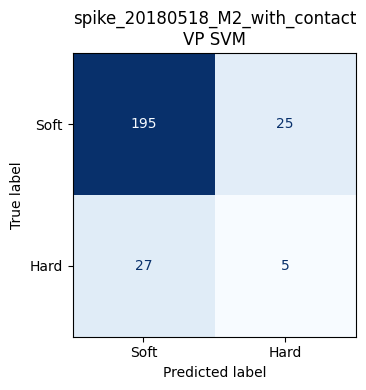

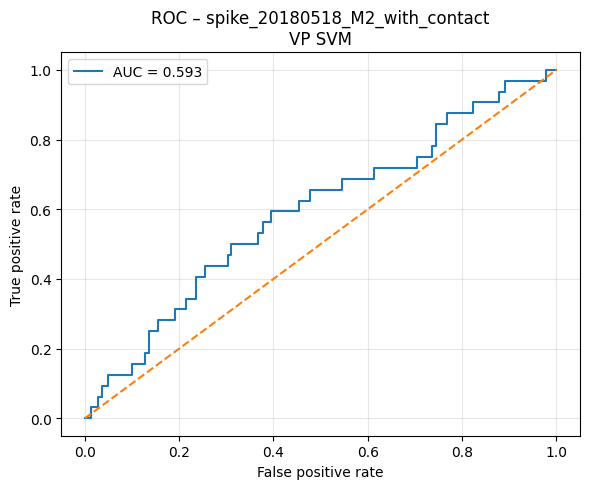

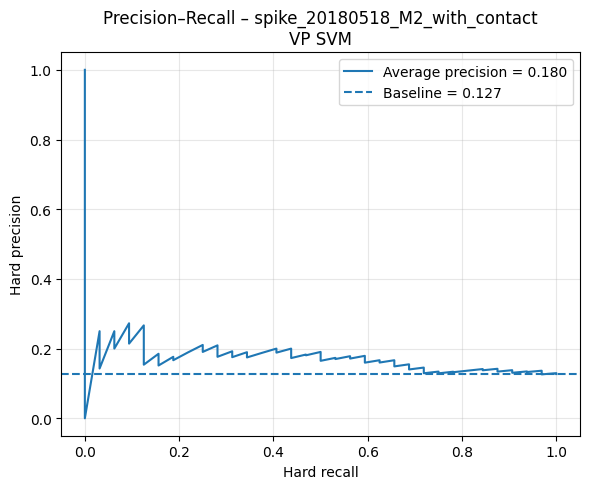


Dataset summary:
                       dataset   model  n_samples  n_soft  n_hard  balanced_accuracy_mean  balanced_accuracy_std  precision_hard_mean  precision_hard_std  recall_hard_mean  recall_hard_std  f1_hard_mean  f1_hard_std  f15_hard_mean  f15_hard_std  specificity_soft_mean  specificity_soft_std  roc_auc_oof  average_precision_oof
spike_20180518_M2_with_contact VP k-NN        252     220      32                0.522042               0.056634             0.200794            0.122811          0.185714         0.056844      0.183443     0.081135       0.182115      0.070350               0.858369              0.080979     0.629616               0.190109
spike_20180518_M2_with_contact  VP SVM        252     220      32                0.519221               0.038509             0.143571            0.094167          0.152381         0.101854      0.146840     0.096405       0.148676      0.098108               0.886061              0.046779     0.592898               0.179517


In [56]:
# ====================================================================
# VICTOR-PURPURA CLASSIFICATION LOOP
# ====================================================================

# --------------------------------------------------------------------
# Model grids used only for Victor-Purpura classification.
# Oversampling has been removed from k-NN.
# The SVM uses gamma_factor instead of an absolute gamma value.
# --------------------------------------------------------------------
'''
vp_parameter_grids_active = {
    
    "VP k-NN": {
        "q": [5, 10, 20, 50],
        "n_neighbors": [1, 3, 5, 7],
        "weights": ["uniform", "distance"],
        "threshold": [0.15, 0.20, 0.25, 0.30] #, 0.35, 0.40, 0.45]
    },

    "VP SVM": {
        "q": [5, 10, 20, 50],
        "gamma_factor": [0.1, 0.25, 0.5, 1, 2, 4],
        "kernel_type": ["laplacian", "rbf_distance"],
        "C": [0.1, 1, 10, 100],
        "class_weight": [
            {0: 1, 1: 2},
            {0: 1, 1: 3},
            {0: 1, 1: 5},
            "balanced"
        ],
        "threshold": [-0.75, -0.50, -0.25, 0.0, 0.25]
    }
}

"VP Balanced RF": {
    "q": [5, 10, 20, 50],
    "n_estimators": [200, 400],
    "max_depth": [3, 4, None],
    "min_samples_leaf": [2, 3, 5],
    "max_features": ["sqrt", None],
    "threshold": [0.25, 0.30, 0.35, 0.40, 0.45, 0.50]
}
'''



all_q_values = sorted(set(
    q
    for grid in vp_parameter_grids_active.values()
    for q in grid["q"]
))


all_dataset_summaries = []
failed_datasets = []


for dataset_index, dataset_folder in enumerate(vp_dataset_folders, start=1):

    dataset_name = dataset_folder.name

    dataset_results_folder = vp_classification_results_root / dataset_name
    dataset_results_folder.mkdir(parents=True, exist_ok=True)

    print("\n")
    print("#" * 80)
    print(f"PROCESSING DATASET {dataset_index}/{len(vp_dataset_folders)}: {dataset_name}")
    print("#" * 80)

    try:

        # ------------------------------------------------------------
        # 1. Load metadata
        # ------------------------------------------------------------

        metadata = pd.read_csv(dataset_folder / "metadata.csv", sep=";")

        required_columns = ["presence", "x", "y"]
        missing_columns = [col for col in required_columns if col not in metadata.columns]

        if missing_columns:
            raise ValueError(f"{dataset_name}: missing columns {missing_columns}")

        y_label = metadata["presence"].astype(int).to_numpy()
        x_coord = pd.to_numeric(metadata["x"], errors="coerce").to_numpy()
        y_coord = pd.to_numeric(metadata["y"], errors="coerce").to_numpy()

        print(f"Samples: {len(y_label)}")
        print(f"Soft: {np.sum(y_label == 0)}")
        print(f"Hard: {np.sum(y_label == 1)}")

        if set(np.unique(y_label)) != {0, 1}:
            raise ValueError(f"{dataset_name}: both classes 0 and 1 must be present.")

        # ------------------------------------------------------------
        # 2. Load precomputed VP distance matrices
        # ------------------------------------------------------------

        distance_matrices = {}

        for q in all_q_values:

            matrix_path = dataset_folder / f"vp_distance_matrix_q_{q}.npy"

            if not matrix_path.exists():
                raise FileNotFoundError(f"Missing VP matrix for q={q}: {matrix_path}")

            distance_matrices[q] = np.load(matrix_path)

        # ------------------------------------------------------------
        # 3. Spatial grouping
        # ------------------------------------------------------------

        x_block = np.floor(x_coord / spatial_block).astype(int)
        y_block = np.floor(y_coord / spatial_block).astype(int)

        groups = np.array([
            f"{xb}_{yb}"
            for xb, yb in zip(x_block, y_block)
        ])

        hard_group_count = len(np.unique(groups[y_label == 1]))
        soft_group_count = len(np.unique(groups[y_label == 0]))

        n_outer_splits = min(5, hard_group_count, soft_group_count)

        if n_outer_splits < 2:
            raise ValueError(f"{dataset_name}: not enough spatial groups for outer CV.")

        outer_cv = StratifiedGroupKFold(
            n_splits=n_outer_splits,
            shuffle=True,
            random_state=RANDOM_STATE
        )

        print(f"Spatial groups: {len(np.unique(groups))}")
        print(f"Outer CV folds: {n_outer_splits}")

        # ------------------------------------------------------------
        # 4. Containers for the current dataset
        # ------------------------------------------------------------

        dataset_summary_rows = []
        dataset_best_parameters = []
        dataset_fold_metrics = []
        dataset_predictions = []

        # ------------------------------------------------------------
        # 5. Loop over VP classifiers
        # ------------------------------------------------------------

        for model_name, parameter_grid in vp_parameter_grids_active.items():

            print("\n")
            print("-" * 60)
            print(f"MODEL: {model_name}")
            print("-" * 60)

            safe_model_name = re.sub(r"[^A-Za-z0-9_-]+", "_", model_name)

            y_pred_oof = np.full(len(y_label), fill_value=-1, dtype=int)
            y_score_oof = np.full(len(y_label), fill_value=np.nan, dtype=float)

            model_fold_metrics = []

            grid_keys = list(parameter_grid.keys())
            grid_values = [parameter_grid[key] for key in grid_keys]

            # --------------------------------------------------------
            # 6. Outer cross-validation
            # --------------------------------------------------------

            for fold_number, (train_idx, test_idx) in enumerate(
                outer_cv.split(np.zeros(len(y_label)), y_label, groups),
                start=1
            ):

                print(f"Outer fold {fold_number}/{n_outer_splits}")

                y_train = y_label[train_idx]
                y_test = y_label[test_idx]
                groups_train = groups[train_idx]

                hard_groups_train = len(np.unique(groups_train[y_train == 1]))
                soft_groups_train = len(np.unique(groups_train[y_train == 0]))

                n_inner_splits = min(4, hard_groups_train, soft_groups_train)

                if n_inner_splits < 2:
                    raise ValueError(f"{dataset_name}, fold {fold_number}: not enough groups for inner CV.")

                inner_cv = StratifiedGroupKFold(
                    n_splits=n_inner_splits,
                    shuffle=True,
                    random_state=RANDOM_STATE
                )

                # ----------------------------------------------------
                # 7. Inner grid search
                # ----------------------------------------------------

                best_inner_score = -np.inf
                best_parameters = None

                for combination in product(*grid_values):

                    parameters = dict(zip(grid_keys, combination))
                    q = parameters["q"]
                    D = distance_matrices[q]

                    inner_scores = []

                    for inner_train_relative, inner_val_relative in inner_cv.split(
                        np.zeros(len(train_idx)),
                        y_train,
                        groups_train
                    ):

                        inner_train_idx = train_idx[inner_train_relative]
                        inner_val_idx = train_idx[inner_val_relative]

                        y_inner_train = y_label[inner_train_idx]
                        y_inner_val = y_label[inner_val_idx]

                        if len(np.unique(y_inner_train)) < 2:
                            continue

                        D_inner_train = D[np.ix_(inner_train_idx, inner_train_idx)]
                        D_inner_val = D[np.ix_(inner_val_idx, inner_train_idx)]

                        # ------------------------------------------------
                        # VP k-NN
                        # ------------------------------------------------

                        if model_name == "VP k-NN":

                            oversampling_ratio = parameters.get("oversampling_ratio", 1.0)

                            hard_idx = inner_train_idx[y_label[inner_train_idx] == 1]
                            soft_idx = inner_train_idx[y_label[inner_train_idx] == 0]

                            if oversampling_ratio > 1.0 and len(hard_idx) > 0:

                                n_hard_target = int(len(hard_idx) * oversampling_ratio)

                                hard_idx_oversampled = np.random.default_rng(
                                    RANDOM_STATE + fold_number
                                ).choice(
                                    hard_idx,
                                    size=n_hard_target,
                                    replace=True
                                )

                                inner_train_idx_used = np.concatenate([
                                    soft_idx,
                                    hard_idx_oversampled
                                ])

                            else:

                                inner_train_idx_used = inner_train_idx

                            y_inner_train_used = y_label[inner_train_idx_used]

                            D_inner_train_used = D[np.ix_(
                                inner_train_idx_used,
                                inner_train_idx_used
                            )]

                            D_inner_val_used = D[np.ix_(
                                inner_val_idx,
                                inner_train_idx_used
                            )]

                            effective_k = min(
                                parameters["n_neighbors"],
                                len(inner_train_idx_used)
                            )

                            classifier = KNeighborsClassifier(
                                n_neighbors=effective_k,
                                metric="precomputed",
                                weights=parameters["weights"]
                            )

                            classifier.fit(
                                D_inner_train_used,
                                y_inner_train_used
                            )

                            proba = classifier.predict_proba(
                                D_inner_val_used
                            )

                            if 1 in classifier.classes_:
                                hard_index = list(classifier.classes_).index(1)
                                y_inner_score = proba[:, hard_index]
                            else:
                                y_inner_score = np.zeros(len(inner_val_idx))

                            threshold = parameters.get("threshold", 0.5)

                            y_inner_pred = (
                                y_inner_score >= threshold
                            ).astype(int)

                        # ------------------------------------------------
                        # VP SVM
                        # ------------------------------------------------

                        elif model_name == "VP SVM":

                            positive_distances = D_inner_train[D_inner_train > 0]

                            if len(positive_distances) == 0:
                                median_distance = 1.0
                            else:
                                median_distance = np.median(positive_distances)

                            gamma = parameters["gamma_factor"] / median_distance

                            if parameters["kernel_type"] == "laplacian":

                                K_inner_train = np.exp(-gamma * D_inner_train)
                                K_inner_val = np.exp(-gamma * D_inner_val)

                            elif parameters["kernel_type"] == "rbf_distance":

                                K_inner_train = np.exp(-gamma * D_inner_train ** 2)
                                K_inner_val = np.exp(-gamma * D_inner_val ** 2)

                            else:

                                raise ValueError(f"Unknown kernel type: {parameters['kernel_type']}")

                            classifier = SVC(
                                kernel="precomputed",
                                C=parameters["C"],
                                class_weight=parameters["class_weight"],
                                cache_size=1000
                            )

                            classifier.fit(K_inner_train, y_inner_train)

                            y_inner_score = classifier.decision_function(K_inner_val)

                            threshold = parameters.get("threshold", 0.0)
                            y_inner_pred = (y_inner_score >= threshold).astype(int)

                        # ------------------------------------------------
                        # VP Balanced Random Forest
                        # ------------------------------------------------
                        '''
                        elif model_name == "VP Balanced RF":

                            classifier = BalancedRandomForestClassifier(
                                n_estimators=parameters["n_estimators"],
                                max_depth=parameters["max_depth"],
                                min_samples_leaf=parameters["min_samples_leaf"],
                                max_features=parameters["max_features"],
                                sampling_strategy="all",
                                replacement=True,
                                bootstrap=False,
                                random_state=RANDOM_STATE,
                                n_jobs=1
                            )

                            classifier.fit(D_inner_train, y_inner_train)

                            proba = classifier.predict_proba(D_inner_val)

                            if 1 in classifier.classes_:
                                hard_index = list(classifier.classes_).index(1)
                                y_inner_score = proba[:, hard_index]
                            else:
                                y_inner_score = np.zeros(len(inner_val_idx))

                            threshold = parameters.get("threshold", 0.5)
                            y_inner_pred = (y_inner_score >= threshold).astype(int)
                        
                        else:

                            raise ValueError(f"Unknown model name: {model_name}")
                        '''
                        # ------------------------------------------------
                        # Inner scoring
                        # ------------------------------------------------
                        # The score favours hard-point detection, but also
                        # penalizes excessive soft-point misclassification.

                        inner_f15 = fbeta_score(
                            y_inner_val,
                            y_inner_pred,
                            beta=1.5,
                            pos_label=1,
                            zero_division=0
                        )

                        inner_balanced_accuracy = balanced_accuracy_score(
                            y_inner_val,
                            y_inner_pred
                        )

                        inner_specificity_soft = recall_score(
                            y_inner_val,
                            y_inner_pred,
                            pos_label=0,
                            zero_division=0
                        )

                        inner_f2 = fbeta_score(
                            y_inner_val,
                            y_inner_pred,
                            beta=2,
                            pos_label=1,
                            zero_division=0
                        )

                        inner_recall_hard = recall_score(
                            y_inner_val,
                            y_inner_pred,
                            pos_label=1,
                            zero_division=0
                        )

                        inner_precision_hard = precision_score(
                            y_inner_val,
                            y_inner_pred,
                            pos_label=1,
                            zero_division=0
                        )

                        inner_specificity_soft = recall_score(
                            y_inner_val,
                            y_inner_pred,
                            pos_label=0,
                            zero_division=0
                        )

                        inner_balanced_accuracy = balanced_accuracy_score(
                            y_inner_val,
                            y_inner_pred
                        )

                        inner_f1_hard = f1_score(
                            y_inner_val,
                            y_inner_pred,
                            pos_label=1,
                            zero_division=0
                        )

                        inner_score = (
                            0.35 * inner_recall_hard
                            + 0.30 * inner_f1_hard
                            + 0.25 * inner_balanced_accuracy
                            + 0.10 * inner_specificity_soft
                        )

                        if inner_specificity_soft < 0.80:
                            inner_score -= 2.0 * (0.80 - inner_specificity_soft)

                        if inner_precision_hard < 0.35:
                            inner_score -= 1.5 * (0.35 - inner_precision_hard)

                        '''
                        inner_score = (
                            0.55 * inner_f15
                            + 0.30 * inner_balanced_accuracy
                            + 0.15 * inner_specificity_soft
                        )

                        if inner_specificity_soft < 0.70:
                            inner_score -= (0.70 - inner_specificity_soft)
                        '''
                        inner_scores.append(inner_score)

                    if len(inner_scores) == 0:
                        continue

                    mean_inner_score = np.mean(inner_scores)

                    if mean_inner_score > best_inner_score:

                        best_inner_score = mean_inner_score
                        best_parameters = parameters.copy()

                if best_parameters is None:
                    raise ValueError(f"{dataset_name}, {model_name}, fold {fold_number}: no valid parameters found.")

                print(f"Best parameters: {best_parameters} | inner selection score = {best_inner_score:.3f}")

                # ----------------------------------------------------
                # 8. Final model on outer training set
                # ----------------------------------------------------

                best_q = best_parameters["q"]
                D_best = distance_matrices[best_q]

                D_outer_train = D_best[np.ix_(train_idx, train_idx)]
                D_outer_test = D_best[np.ix_(test_idx, train_idx)]

                used_gamma = np.nan

                # ----------------------------------------------------
                # Final VP k-NN
                # ----------------------------------------------------

                if model_name == "VP k-NN":

                    oversampling_ratio = best_parameters.get("oversampling_ratio", 1.0)

                    hard_idx = train_idx[y_label[train_idx] == 1]
                    soft_idx = train_idx[y_label[train_idx] == 0]

                    if oversampling_ratio > 1.0 and len(hard_idx) > 0:

                        n_hard_target = int(len(hard_idx) * oversampling_ratio)

                        hard_idx_oversampled = np.random.default_rng(
                            RANDOM_STATE + fold_number
                        ).choice(
                            hard_idx,
                            size=n_hard_target,
                            replace=True
                        )

                        train_idx_used = np.concatenate([
                            soft_idx,
                            hard_idx_oversampled
                        ])

                    else:

                        train_idx_used = train_idx

                    y_train_used = y_label[train_idx_used]

                    D_outer_train_used = D_best[np.ix_(
                        train_idx_used,
                        train_idx_used
                    )]

                    D_outer_test_used = D_best[np.ix_(
                        test_idx,
                        train_idx_used
                    )]

                    effective_k = min(
                        best_parameters["n_neighbors"],
                        len(train_idx_used)
                    )

                    final_classifier = KNeighborsClassifier(
                        n_neighbors=effective_k,
                        metric="precomputed",
                        weights=best_parameters["weights"]
                    )

                    final_classifier.fit(
                        D_outer_train_used,
                        y_train_used
                    )

                    proba = final_classifier.predict_proba(
                        D_outer_test_used
                    )

                    if 1 in final_classifier.classes_:
                        hard_index = list(final_classifier.classes_).index(1)
                        y_test_score = proba[:, hard_index]
                    else:
                        y_test_score = np.zeros(len(test_idx))

                    threshold = best_parameters.get("threshold", 0.5)

                    y_test_pred = (
                        y_test_score >= threshold
                    ).astype(int)
                # ----------------------------------------------------
                # Final VP SVM
                # ----------------------------------------------------

                elif model_name == "VP SVM":

                    positive_distances = D_outer_train[D_outer_train > 0]

                    if len(positive_distances) == 0:
                        median_distance = 1.0
                    else:
                        median_distance = np.median(positive_distances)

                    used_gamma = best_parameters["gamma_factor"] / median_distance

                    if best_parameters["kernel_type"] == "laplacian":

                        K_outer_train = np.exp(-used_gamma * D_outer_train)
                        K_outer_test = np.exp(-used_gamma * D_outer_test)

                    elif best_parameters["kernel_type"] == "rbf_distance":

                        K_outer_train = np.exp(-used_gamma * D_outer_train ** 2)
                        K_outer_test = np.exp(-used_gamma * D_outer_test ** 2)

                    else:

                        raise ValueError(f"Unknown kernel type: {best_parameters['kernel_type']}")

                    final_classifier = SVC(
                        kernel="precomputed",
                        C=best_parameters["C"],
                        class_weight=best_parameters["class_weight"],
                        cache_size=1000
                    )

                    final_classifier.fit(K_outer_train, y_train)

                    y_test_score = final_classifier.decision_function(K_outer_test)

                    threshold = best_parameters.get("threshold", 0.0)
                    y_test_pred = (y_test_score >= threshold).astype(int)

                # ----------------------------------------------------
                # Final VP Balanced RF
                # ----------------------------------------------------
                '''
                elif model_name == "VP Balanced RF":

                    final_classifier = BalancedRandomForestClassifier(
                        n_estimators=best_parameters["n_estimators"],
                        max_depth=best_parameters["max_depth"],
                        min_samples_leaf=best_parameters["min_samples_leaf"],
                        max_features=best_parameters["max_features"],
                        sampling_strategy="all",
                        replacement=True,
                        bootstrap=False,
                        random_state=RANDOM_STATE,
                        n_jobs=1
                    )

                    final_classifier.fit(D_outer_train, y_train)

                    proba = final_classifier.predict_proba(D_outer_test)

                    if 1 in final_classifier.classes_:
                        hard_index = list(final_classifier.classes_).index(1)
                        y_test_score = proba[:, hard_index]
                    else:
                        y_test_score = np.zeros(len(test_idx))

                    threshold = best_parameters.get("threshold", 0.5)
                    y_test_pred = (y_test_score >= threshold).astype(int)

                else:

                    raise ValueError(f"Unknown model name: {model_name}")
                '''
                # ----------------------------------------------------
                # Safety checks
                # ----------------------------------------------------

                if len(y_test_pred) != len(test_idx):
                    raise ValueError(
                        f"Prediction length mismatch: "
                        f"len(y_test_pred)={len(y_test_pred)}, "
                        f"len(test_idx)={len(test_idx)}"
                    )

                if len(y_test_score) != len(test_idx):
                    raise ValueError(
                        f"Score length mismatch: "
                        f"len(y_test_score)={len(y_test_score)}, "
                        f"len(test_idx)={len(test_idx)}"
                    )

                y_pred_oof[test_idx] = y_test_pred
                y_score_oof[test_idx] = y_test_score

                # ----------------------------------------------------
                # Save best parameters for this outer fold
                # ----------------------------------------------------

                parameter_row = {
                    "dataset": dataset_name,
                    "model": model_name,
                    "outer_fold": fold_number,
                    "best_inner_selection_score": best_inner_score,
                    "used_gamma": used_gamma
                }

                parameter_row.update(best_parameters)

                dataset_best_parameters.append(parameter_row)

                # ----------------------------------------------------
                # Fold metrics
                # ----------------------------------------------------

                fold_metric_row = {
                    "dataset": dataset_name,
                    "model": model_name,
                    "outer_fold": fold_number,
                    "q": best_parameters["q"],
                    "threshold": best_parameters.get("threshold", np.nan),
                    "used_gamma": used_gamma,
                    "balanced_accuracy": balanced_accuracy_score(y_test, y_test_pred),
                    "precision_hard": precision_score(y_test, y_test_pred, pos_label=1, zero_division=0),
                    "recall_hard": recall_score(y_test, y_test_pred, pos_label=1, zero_division=0),
                    "f1_hard": f1_score(y_test, y_test_pred, pos_label=1, zero_division=0),
                    "f15_hard": fbeta_score(y_test, y_test_pred, beta=1.5, pos_label=1, zero_division=0),
                    "specificity_soft": recall_score(y_test, y_test_pred, pos_label=0, zero_division=0)
                }

                model_fold_metrics.append(fold_metric_row)
                dataset_fold_metrics.append(fold_metric_row)

            # --------------------------------------------------------
            # 9. Model summary
            # --------------------------------------------------------

            if np.any(y_pred_oof == -1):
                raise RuntimeError(f"{dataset_name}, {model_name}: some samples have no OOF prediction.")

            model_fold_metrics_table = pd.DataFrame(model_fold_metrics)

            summary_row = {
                "dataset": dataset_name,
                "model": model_name,
                "n_samples": len(y_label),
                "n_soft": int(np.sum(y_label == 0)),
                "n_hard": int(np.sum(y_label == 1))
            }

            for metric_name in [
                "balanced_accuracy",
                "precision_hard",
                "recall_hard",
                "f1_hard",
                "f15_hard",
                "specificity_soft"
            ]:

                summary_row[f"{metric_name}_mean"] = model_fold_metrics_table[metric_name].mean()
                summary_row[f"{metric_name}_std"] = model_fold_metrics_table[metric_name].std(ddof=1)

            summary_row["roc_auc_oof"] = roc_auc_score(y_label, y_score_oof)
            summary_row["average_precision_oof"] = average_precision_score(y_label, y_score_oof)

            dataset_summary_rows.append(summary_row)

            if np.any(y_pred_oof == -1):
                raise RuntimeError(f"{dataset_name}, {model_name}: some samples have no OOF prediction.")

            '''
            # --------------------------------------------------------
            # Threshold analysis for VP k-NN
            # --------------------------------------------------------

            if model_name == "VP k-NN":

                threshold_rows = []

                for threshold_test in np.arange(0.10, 0.75, 0.05):

                    y_pred_threshold = (y_score_oof >= threshold_test).astype(int)

                    threshold_rows.append({
                        "threshold": threshold_test,
                        "precision_hard": precision_score(y_label, y_pred_threshold, pos_label=1, zero_division=0),
                        "recall_hard": recall_score(y_label, y_pred_threshold, pos_label=1, zero_division=0),
                        "f1_hard": f1_score(y_label, y_pred_threshold, pos_label=1, zero_division=0),
                        "specificity_soft": recall_score(y_label, y_pred_threshold, pos_label=0, zero_division=0),
                        "balanced_accuracy": balanced_accuracy_score(y_label, y_pred_threshold)
                    })

                threshold_table = pd.DataFrame(threshold_rows)

                threshold_table.to_csv(
                    dataset_results_folder / f"threshold_analysis_{safe_model_name}.csv",
                    sep=";",
                    index=False
                )

                print("\nThreshold analysis for VP k-NN:")
                print(threshold_table.to_string(index=False))
                '''

            model_fold_metrics_table = pd.DataFrame(model_fold_metrics)

            summary_row = {
                "dataset": dataset_name,
                "model": model_name,
                "n_samples": len(y_label),
                "n_soft": int(np.sum(y_label == 0)),
                "n_hard": int(np.sum(y_label == 1))
            }

            # --------------------------------------------------------
            # 10. Classification report
            # --------------------------------------------------------

            report = classification_report(
                y_label,
                y_pred_oof,
                labels=[0, 1],
                target_names=["soft", "hard"],
                output_dict=True,
                zero_division=0
            )

            report_table = pd.DataFrame(report).transpose()

            report_table.to_csv(
                dataset_results_folder / f"classification_report_{safe_model_name}.csv",
                sep=";"
            )

            # --------------------------------------------------------
            # 11. Confusion matrix
            # --------------------------------------------------------

            cm = confusion_matrix(y_label, y_pred_oof, labels=[0, 1])

            figure, axis = plt.subplots(figsize=(5, 4))

            ConfusionMatrixDisplay(
                confusion_matrix=cm,
                display_labels=["Soft", "Hard"]
            ).plot(ax=axis, values_format="d", colorbar=False, cmap="Blues")

            axis.set_title(f"{dataset_name}\n{model_name}")

            figure.tight_layout()

            figure.savefig(
                dataset_results_folder / f"confusion_matrix_{safe_model_name}.png",
                dpi=300,
                bbox_inches="tight"
            )

            if show_plots:
                plt.show()

            plt.close(figure)

            # --------------------------------------------------------
            # 12. ROC curve
            # --------------------------------------------------------

            fpr, tpr, _ = roc_curve(y_label, y_score_oof)
            roc_auc = roc_auc_score(y_label, y_score_oof)

            figure, axis = plt.subplots(figsize=(6, 5))

            axis.plot(fpr, tpr, label=f"AUC = {roc_auc:.3f}")
            axis.plot([0, 1], [0, 1], linestyle="--")
            axis.set_xlabel("False positive rate")
            axis.set_ylabel("True positive rate")
            axis.set_title(f"ROC – {dataset_name}\n{model_name}")
            axis.legend()
            axis.grid(alpha=0.3)

            figure.tight_layout()

            figure.savefig(
                dataset_results_folder / f"roc_curve_{safe_model_name}.png",
                dpi=300,
                bbox_inches="tight"
            )

            if show_plots:
                plt.show()

            plt.close(figure)

            # --------------------------------------------------------
            # 13. Precision-Recall curve
            # --------------------------------------------------------

            precision_curve, recall_curve, _ = precision_recall_curve(y_label, y_score_oof)
            average_precision = average_precision_score(y_label, y_score_oof)
            hard_prevalence = np.mean(y_label == 1)

            figure, axis = plt.subplots(figsize=(6, 5))

            axis.plot(recall_curve, precision_curve, label=f"Average precision = {average_precision:.3f}")
            axis.axhline(hard_prevalence, linestyle="--", label=f"Baseline = {hard_prevalence:.3f}")
            axis.set_xlabel("Hard recall")
            axis.set_ylabel("Hard precision")
            axis.set_title(f"Precision–Recall – {dataset_name}\n{model_name}")
            axis.legend()
            axis.grid(alpha=0.3)

            figure.tight_layout()

            figure.savefig(
                dataset_results_folder / f"precision_recall_{safe_model_name}.png",
                dpi=300,
                bbox_inches="tight"
            )

            if show_plots:
                plt.show()

            plt.close(figure)

            # --------------------------------------------------------
            # 14. OOF predictions
            # --------------------------------------------------------

            predictions_table = pd.DataFrame({
                "dataset": dataset_name,
                "model": model_name,
                "true_presence": y_label,
                "predicted_presence": y_pred_oof,
                "prediction_score": y_score_oof,
                "x": x_coord,
                "y": y_coord
            })

            if "diameter" in metadata.columns:
                predictions_table["diameter"] = metadata["diameter"].to_numpy()

            dataset_predictions.append(predictions_table)

        # ------------------------------------------------------------
        # 15. Save all results for current dataset
        # ------------------------------------------------------------

        summary_table = pd.DataFrame(dataset_summary_rows)
        best_parameters_table = pd.DataFrame(dataset_best_parameters)
        fold_metrics_table = pd.DataFrame(dataset_fold_metrics)
        predictions_table = pd.concat(dataset_predictions, ignore_index=True)

        summary_table.to_csv(
            dataset_results_folder / "vp_classification_summary.csv",
            sep=";",
            index=False
        )

        best_parameters_table.to_csv(
            dataset_results_folder / "vp_best_parameters.csv",
            sep=";",
            index=False
        )

        fold_metrics_table.to_csv(
            dataset_results_folder / "vp_fold_metrics.csv",
            sep=";",
            index=False
        )

        predictions_table.to_csv(
            dataset_results_folder / "vp_oof_predictions.csv",
            sep=";",
            index=False
        )

        all_dataset_summaries.append(summary_table)

        print("\nDataset summary:")
        print(summary_table.to_string(index=False))

    except Exception as error:

        print(f"Error processing {dataset_name}: {error}")

        failed_datasets.append({
            "dataset": dataset_name,
            "error": str(error)
        })

In [57]:
# ====================================================================
# CHECK VP DISTANCE SEPARABILITY
# ====================================================================

q_to_check = 20
D = distance_matrices[q_to_check]

same_soft = []
same_hard = []
different = []

for i in range(len(y_label)):
    for j in range(i + 1, len(y_label)):

        if y_label[i] == 0 and y_label[j] == 0:
            same_soft.append(D[i, j])

        elif y_label[i] == 1 and y_label[j] == 1:
            same_hard.append(D[i, j])

        else:
            different.append(D[i, j])

print(f"q = {q_to_check}")
print(f"Mean soft-soft distance: {np.mean(same_soft):.3f}")
print(f"Mean hard-hard distance: {np.mean(same_hard):.3f}")
print(f"Mean soft-hard distance: {np.mean(different):.3f}")

q = 20
Mean soft-soft distance: 91.327
Mean hard-hard distance: 86.506
Mean soft-hard distance: 90.665


In [58]:
# ====================================================================
# SAVE GLOBAL SUMMARY
# ====================================================================

if len(all_dataset_summaries) > 0:

    global_summary = pd.concat(all_dataset_summaries, ignore_index=True)

    global_summary.to_csv(
        vp_classification_results_root / "all_vp_classification_summary.csv",
        sep=";",
        index=False
    )

    print("\nGLOBAL VICTOR-PURPURA CLASSIFICATION SUMMARY")
    print(global_summary.to_string(index=False))


if len(failed_datasets) > 0:

    failed_table = pd.DataFrame(failed_datasets)

    failed_table.to_csv(
        vp_classification_results_root / "failed_vp_classification_datasets.csv",
        sep=";",
        index=False
    )

    print("\nFAILED DATASETS")
    print(failed_table.to_string(index=False))

else:
    print("\nAll datasets were classified successfully.")


GLOBAL VICTOR-PURPURA CLASSIFICATION SUMMARY
                                      dataset   model  n_samples  n_soft  n_hard  balanced_accuracy_mean  balanced_accuracy_std  precision_hard_mean  precision_hard_std  recall_hard_mean  recall_hard_std  f1_hard_mean  f1_hard_std  f15_hard_mean  f15_hard_std  specificity_soft_mean  specificity_soft_std  roc_auc_oof  average_precision_oof
    spike_20180424_M1_Chattering_with_contact VP k-NN        252     206      46                0.659037               0.128101             0.540952            0.237490          0.453333         0.223248      0.455678     0.177634       0.447583      0.185463               0.864740              0.143319     0.658506               0.385091
    spike_20180424_M1_Chattering_with_contact  VP SVM        252     206      46                0.677532               0.102593             0.427510            0.132286          0.540556         0.228181      0.454306     0.120091       0.478048      0.146510             

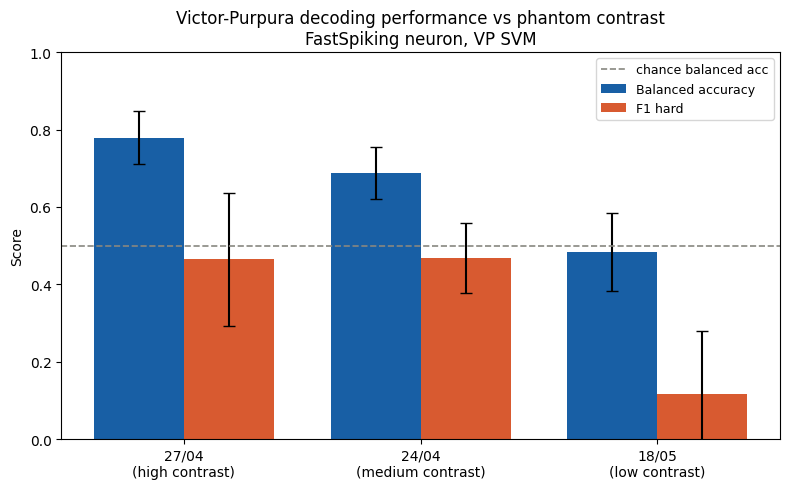

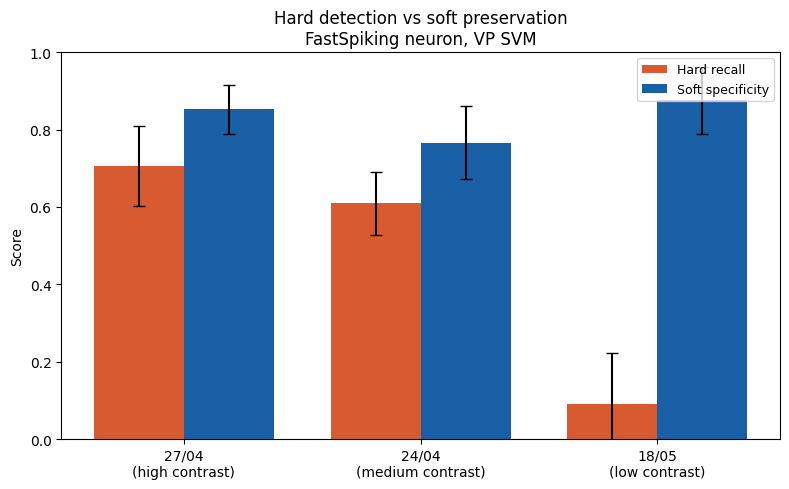


Cross-phantom VP SVM comparison:
                 phantom  bal_acc_mean  bal_acc_std  f1_mean   f1_std  recall_hard_mean  recall_hard_std  specificity_soft_mean  specificity_soft_std
  27/04\n(high contrast)      0.779303     0.069664 0.464560 0.171888          0.706667         0.103145               0.851939              0.062780
24/04\n(medium contrast)      0.687688     0.068413 0.468446 0.090615          0.609444         0.081546               0.765931              0.094987
   18/05\n(low contrast)      0.483196     0.101595 0.116667 0.162447          0.090476         0.130844               0.875916              0.086704


In [59]:
# ====================================================================
# CROSS-PHANTOM COMPARISON PLOT
# FastSpiking neuron, Victor-Purpura SVM classifier
# ====================================================================
# --------------------------------------------------------------------
# 1. Source table
# --------------------------------------------------------------------
# If a global VP summary already exists in memory, use it.
# Otherwise, rebuild it by loading the per-dataset summary files.

if "global_summary" in globals():

    summary_df = global_summary.copy()

else:

    summary_files = sorted(
        Path(vp_classification_results_root).glob("*/vp_classification_summary.csv")
    )

    if len(summary_files) == 0:
        raise FileNotFoundError(
            f"No vp_classification_summary.csv files found in {vp_classification_results_root}"
        )

    summary_df = pd.concat(
        [pd.read_csv(file, sep=";") for file in summary_files],
        ignore_index=True
    )


# --------------------------------------------------------------------
# 2. FastSpiking datasets ordered by decreasing phantom contrast
# --------------------------------------------------------------------

phantom_datasets = [
    ("spike_20180427_M1_FastSpiking_with_contact", "27/04\n(high contrast)"),
    ("spike_20180424_M1_FastSpiking_with_contact", "24/04\n(medium contrast)"),
    ("spike_20180518_M2_FastSpiking_with_contact", "18/05\n(low contrast)")
]

model_name = "VP SVM"


# --------------------------------------------------------------------
# 3. Collect metrics for each phantom
# --------------------------------------------------------------------

plot_rows = []

for dataset_name, phantom_label in phantom_datasets:

    row = summary_df[
        (summary_df["dataset"] == dataset_name)
        & (summary_df["model"] == model_name)
    ]

    if row.empty:
        print(f"WARNING: no row found for {dataset_name} / {model_name}")
        continue

    row = row.iloc[0]

    plot_rows.append({
        "phantom": phantom_label,
        "bal_acc_mean": row["balanced_accuracy_mean"],
        "bal_acc_std": row["balanced_accuracy_std"],
        "f1_mean": row["f1_hard_mean"],
        "f1_std": row["f1_hard_std"],
        "recall_hard_mean": row["recall_hard_mean"],
        "recall_hard_std": row["recall_hard_std"],
        "specificity_soft_mean": row["specificity_soft_mean"],
        "specificity_soft_std": row["specificity_soft_std"]
    })

plot_df = pd.DataFrame(plot_rows)

if plot_df.empty:
    raise ValueError("No matching FastSpiking / VP SVM rows were found.")


# --------------------------------------------------------------------
# 4. Grouped bar chart: balanced accuracy and F1-hard
# --------------------------------------------------------------------

positions = np.arange(len(plot_df))
bar_width = 0.38

fig, ax = plt.subplots(figsize=(8, 5))

ax.bar(
    positions - bar_width / 2,
    plot_df["bal_acc_mean"],
    yerr=plot_df["bal_acc_std"],
    width=bar_width,
    color="#185FA5",
    capsize=4,
    label="Balanced accuracy"
)

ax.bar(
    positions + bar_width / 2,
    plot_df["f1_mean"],
    yerr=plot_df["f1_std"],
    width=bar_width,
    color="#D85A30",
    capsize=4,
    label="F1 hard"
)

ax.axhline(
    0.5,
    color="#888780",
    linestyle="--",
    linewidth=1.2,
    label="chance balanced acc"
)

ax.set_xticks(positions)
ax.set_xticklabels(plot_df["phantom"])
ax.set_ylabel("Score")
ax.set_ylim(0, 1)

ax.set_title(
    "Victor-Purpura decoding performance vs phantom contrast\n"
    "FastSpiking neuron, VP SVM"
)

ax.legend(loc="upper right", fontsize=9)

fig.tight_layout()

fig.savefig(
    Path(vp_classification_results_root) / "cross_phantom_fastspiking_vp_svm_balacc_f1.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()
plt.close(fig)


# --------------------------------------------------------------------
# 5. Optional second plot: hard recall vs soft specificity
# --------------------------------------------------------------------
# This is useful because your goal is to identify hard points,
# but without misclassifying too many soft points.

fig, ax = plt.subplots(figsize=(8, 5))

ax.bar(
    positions - bar_width / 2,
    plot_df["recall_hard_mean"],
    yerr=plot_df["recall_hard_std"],
    width=bar_width,
    color="#D85A30",
    capsize=4,
    label="Hard recall"
)

ax.bar(
    positions + bar_width / 2,
    plot_df["specificity_soft_mean"],
    yerr=plot_df["specificity_soft_std"],
    width=bar_width,
    color="#185FA5",
    capsize=4,
    label="Soft specificity"
)

ax.set_xticks(positions)
ax.set_xticklabels(plot_df["phantom"])
ax.set_ylabel("Score")
ax.set_ylim(0, 1)

ax.set_title(
    "Hard detection vs soft preservation\n"
    "FastSpiking neuron, VP SVM"
)

ax.legend(loc="upper right", fontsize=9)

fig.tight_layout()

fig.savefig(
    Path(vp_classification_results_root) / "cross_phantom_fastspiking_vp_svm_recall_specificity.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()
plt.close(fig)


# --------------------------------------------------------------------
# 6. Save plotted values
# --------------------------------------------------------------------

plot_df.to_csv(
    Path(vp_classification_results_root) / "cross_phantom_fastspiking_vp_svm_values.csv",
    sep=";",
    index=False
)

print("\nCross-phantom VP SVM comparison:")
print(plot_df.to_string(index=False))